## Summary

**Prototype:** a Random Forest on 3-month Sentinel-2 windows (section 4). It is trained on the KML calendar labels and NAMRIA land-use non-crop samples from 2019-2023 and tested on 2024-2026.

| Question | Result | What it means |
|---|---|---|
| Agreement with the calendar in later years | macro-F1 **0.59**; 0.65 per polygon-window (230 polygon-windows: 5 KML polygons + 4 land-use types) | Same polygons and months as training, and the calendar labels repeat every year. This is agreement, not accuracy. |
| Month-only control | macro-F1 0.37 | The imagery adds about 0.22 over knowing the month. |
| Crop vs non-crop on held-out land-use blocks | 77-90% of non-crop found: forest 90-93%, pasture 96-99%, built-up 68-73% | Uses non-crop samples independent of the features. 17% of crop windows are called non-crop. |
| The v1 non-crop score (~95%) | A model trained on the v1 NDVI-rule anchors finds 61% of the land-use non-crop samples, and 28% of built-up | The v1 score was mostly circular. |
| Crop type on unseen fields (section 12) | Best method (DTW) 22% correct over carrot, cabbage and other_crop; random guessing 25% | **Not feasible with the current labels.** Calendar-only gets 33% by always answering other_crop. Potato is in one field only and cannot be tested. |

Tested and turned off:
- **Clear-composite count as a feature:** no effect (0.592 with and without it).
- **Pseudo-labels:** no gain on the inner years; 99.6% of the accepted ones are non-crop; turned off by the 11.6 gate.

**Maps (section 10):** drawn for **2024**, the year with the clearest imagery: 81% of ROI pixels can be mapped on average over the three windows, against 71% for 2025. 2024 is a test year. Most pixels are still uncertain (58-91% per window, top probability < 0.6), so read the maps as where the model is unsure, not as a crop map.

**Data needed next:** dated crop observations for at least 5 fields each of carrot, cabbage and potato (template in 11.2, 45 candidate sites in 11.3).

**Limits of the non-crop samples:**
- The land-use map is a 2023 snapshot applied to all years.

# 8. Atok weak supervision prototype (v2)

Weakly supervised crop-type mapping for the Atok/Paoay ROI using Sentinel-2 half-month composites and the crop-calendar KML. Classes: carrot, cabbage, potato, other crop and non-crop, with an uncertain label when the evidence is weak.

Sections:
1. KML polygons and calendar priors
2. Sentinel-2 composites (2019-2026) and indices
3. Windows, features and weak labels
4. Experiment A: supervised baseline
5. Experiment B: clustering
6. Experiment C: TWDTW matching
7. Experiment D: TWDTW with calendar prior
8. Experiment E: pseudo-labels
9. Coverage and calibration
10. Maps for the clearest year
11. Next steps toward ground truth
12. Testing on unseen fields
13. Interactive map site

All labels come from the KML calendars, so the scores measure agreement with the calendars, not field-checked accuracy. The PMI/PEMI potato indices are not used because the composites have no B6, B7, B8A or B12.

In [1]:
from pathlib import Path
import json
import os
import re
import warnings
import xml.etree.ElementTree as ET

import geopandas as gpd
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from IPython.display import display
from matplotlib.colors import ListedColormap
from pyproj import Transformer
from rasterio.features import geometry_mask
from rasterio.windows import Window, from_bounds
from shapely import transform as shapely_transform, union_all
from shapely.geometry import Polygon, mapping
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (accuracy_score, adjusted_rand_score, average_precision_score,
                             balanced_accuracy_score, cohen_kappa_score, confusion_matrix,
                             f1_score, precision_recall_fscore_support)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=RuntimeWarning)
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
settings_path = Path("settings.local.json")
local_settings = json.loads(settings_path.read_text()) if settings_path.exists() else {}
report_folder = Path(local_settings.get("report_root", "./sen4agrinet_work/inventory")).expanduser().resolve()
analysis_root = Path(local_settings.get("analysis_root", "./analysis")).expanduser().resolve()  # outputs of notebooks 07-10

# The shared THS-SENTINEL2 folder: set atok_imagery_root in settings.local.json to wherever it syncs on this machine.
IMAGERY_ROOT = Path(local_settings.get("atok_imagery_root", "")).expanduser()
KML_PATH = Path(local_settings.get("atok_kml_path", "./data/atok/atok_benguet.kml")).expanduser()
LANDUSE_PATH = Path(local_settings.get("atok_landuse_path", "./data/atok/elum2023_benguet.gpkg")).expanduser()  # NAMRIA ELUM 2023, Benguet
missing = [f"{name} ({key}): {path}" for name, key, path, found in (
    ("Imagery folder", "atok_imagery_root", IMAGERY_ROOT, IMAGERY_ROOT.is_dir() and str(IMAGERY_ROOT) != "."),
    ("KML", "atok_kml_path", KML_PATH, KML_PATH.is_file()),
    ("Land-use map", "atok_landuse_path", LANDUSE_PATH, LANDUSE_PATH.is_file())) if not found]
if missing:
    raise FileNotFoundError("Missing input(s); set the paths in settings.local.json (see settings.example.json):\n  " + "\n  ".join(missing))
OUTPUT = analysis_root / "atok" / "weak_labels"  # earlier v1 (clear_steps as a feature): analysis/atok/archive/weak_labels_v1
FIGURES = OUTPUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

SEED = 42
YEARS = list(range(2019, 2027))           # 2016-2018 hold too few composites
WINDOW = 6                                # half-month composites per window = 3 months
MIN_VALID = 4                             # valid composites required in a window; gaps are interpolated
TRAIN_YEARS, TEST_YEARS = range(2019, 2024), range(2024, 2027)
CLASSES = ["carrot", "cabbage", "potato", "other_crop", "non_crop"]
CROP_CLASSES = CLASSES[:4]
BANDS = ["B3", "B4", "B5", "B8", "B11"]
VARS = BANDS + ["NDVI", "NDRE", "NDMI"]
INDICES = ["NDVI", "NDRE", "NDMI"]
COLORS = {"carrot": "#F58518", "cabbage": "#54A24B", "potato": "#B279A2", "other_crop": "#4C78A8",
          "non_crop": "#9D9D9D", "uncertain": "#FFFFFF"}
pd.set_option("display.precision", 3)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
print("Imagery:", IMAGERY_ROOT, "| exists:", IMAGERY_ROOT.is_dir())
print("KML:", KML_PATH, "| exists:", KML_PATH.is_file())
print("Land use:", LANDUSE_PATH, "| exists:", LANDUSE_PATH.is_file())
print("Output:", OUTPUT)

Imagery: /Users/almiravelasquez/Library/CloudStorage/GoogleDrive-almira_zabrina_velasquez@dlsu.edu.ph/.shortcut-targets-by-id/1SpZXFBHb16lC2M8_i6SHtcce4H87-aB4/THS-SENTINEL2 | exists: True
KML: data/atok/atok_benguet.kml | exists: True
Land use: data/atok/elum2023_benguet.gpkg | exists: True
Output: /Users/almiravelasquez/workspaces/external-crop-data-classification/sen4agrinet_work/analysis/atok_weak_supervision_v2


## 1. KML polygons and calendar priors

The crop calendars in the KML descriptions were transcribed by hand into rows of area, crop and months (planting to harvest). Each source has a weight: 1.0 for the explicit crop polygons (B1, B2), 0.85 for the farmer calendar (Area 2), 0.7 for the single-crop calendars (Areas 3 and 5) and 0.5 for the multi-crop calendars (Areas 1 and 4).

- B1, B2, Area 2, Area 3 and Area 5 give the weak labels.
- Areas 1 and 4 have overlapping calendars, so they are only averaged into a regional prior (K) and their pixels are left unlabeled.
- Polygon 3 and the rest of the ROI are unlabeled.

Each monthly prior mixes the area calendar with a uniform crop prior according to its weight, then is smoothed over the neighbouring months. Months with no information get a uniform prior, so no class ever gets zero probability.

,folder,name,description
0,Crop Area,B2,- lettuce all year
1,Crop Area,B1,- Cabbage (Jan-Feb)\n- Carrot (March-June)
2,00 - Atok Boundary,Atok,ADM4_EN: Paoay\nADM4_PCODE: PH1401101005\nADM4...
3,00 - Atok Boundary,Polygon 3,ADM4_EN: \nADM4_PCODE: \nADM4_REF: \nADM3_PCOD...
4,00 - Region of Interest,Region of Interest,
5,00 - Region of Interest,Area 1,Agricultural system: Multiple cropping / crop ...
6,00 - Region of Interest,Area 2,March–June: Potato — planting/growing; harvest...
7,00 - Region of Interest,Area 3,Cabbage\n- Planting months: Year-round (Januar...
8,00 - Region of Interest,Area 4,Cabbage\n- Planting months: April–September\n-...
9,00 - Region of Interest,Area 5,Crops and plants cultivated: A variety of orna...


,area,crop_name,target_class,months,evidence_type,confidence_weight
0,B1,cabbage,cabbage,"1,2",explicit_crop_polygon,1.00
1,B1,carrot,carrot,"3,4,5,6",explicit_crop_polygon,1.00
2,B2,lettuce,other_crop,"1,2,3,4,5,6,7,8,9,10,11,12",explicit_crop_polygon,1.00
3,Area 2,potato,potato,"3,4,5,6",direct_farmer_calendar,0.85
4,Area 2,cabbage,cabbage,"7,8,9,10,11",direct_farmer_calendar,0.85
5,Area 2,carrot,carrot,"11,12,1,2",direct_farmer_calendar,0.85
6,Area 2,radish,other_crop,"1,2,3,4,5,6,7,8,9,10,11,12",alternative_crop_timing_unknown,0.15
7,Area 3,cabbage,cabbage,"1,2,3,4,5,6,7,8,9,10,11,12",single_crop_calendar,0.70
8,Area 5,ornamentals / seedbeds,other_crop,"1,2,3,4,5,6,7,8,9,10,11,12",single_crop_calendar,0.70
9,Area 1,carrot,carrot,"4,5,6,7,8,9,10,11,12",regional_calendar,0.50


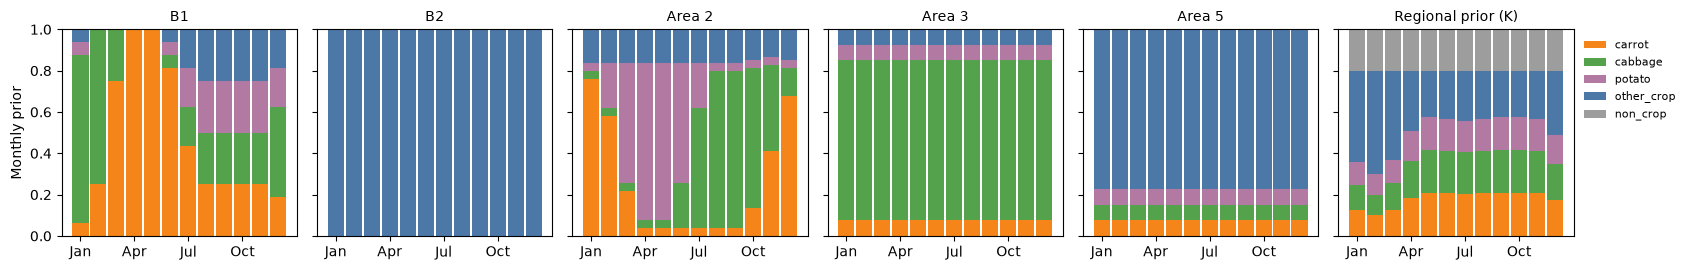

In [2]:
KML_NS = {"k": "http://www.opengis.net/kml/2.2"}


def read_kml(path):
    rows = []
    for folder in ET.parse(path).getroot().iter(f"{{{KML_NS['k']}}}Folder"):
        for placemark in folder.findall("k:Placemark", KML_NS):
            description = placemark.find("k:description", KML_NS)
            coordinates = placemark.find(".//k:coordinates", KML_NS).text.split()
            rows.append({
                "folder": folder.find("k:name", KML_NS).text,
                "name": placemark.find("k:name", KML_NS).text,
                "description": re.sub(r"<br\s*/?>", "\n", description.text or "") if description is not None else "",
                "geometry": Polygon([tuple(map(float, c.split(",")[:2])) for c in coordinates]),
            })
    return pd.DataFrame(rows)


def months(first, last):
    return [((first - 1 + offset) % 12) + 1 for offset in range((last - first) % 12 + 1)]


ALL_MONTHS = months(1, 12)
# area, crop named in the KML, model class, occupied months, evidence type, evidence weight
CALENDAR = [
    ("B1", "cabbage", "cabbage", months(1, 2), "explicit_crop_polygon", 1.0),
    ("B1", "carrot", "carrot", months(3, 6), "explicit_crop_polygon", 1.0),
    ("B2", "lettuce", "other_crop", ALL_MONTHS, "explicit_crop_polygon", 1.0),
    ("Area 2", "potato", "potato", months(3, 6), "direct_farmer_calendar", 0.85),
    ("Area 2", "cabbage", "cabbage", months(7, 11), "direct_farmer_calendar", 0.85),
    ("Area 2", "carrot", "carrot", months(11, 2), "direct_farmer_calendar", 0.85),
    ("Area 2", "radish", "other_crop", ALL_MONTHS, "alternative_crop_timing_unknown", 0.15),
    ("Area 3", "cabbage", "cabbage", ALL_MONTHS, "single_crop_calendar", 0.7),
    ("Area 5", "ornamentals / seedbeds", "other_crop", ALL_MONTHS, "single_crop_calendar", 0.7),
    ("Area 1", "carrot", "carrot", months(4, 12), "regional_calendar", 0.5),
    ("Area 1", "cabbage", "cabbage", months(4, 12), "regional_calendar", 0.5),
    ("Area 1", "white potato", "potato", months(4, 8) + months(9, 12), "regional_calendar", 0.5),
    ("Area 1", "radish", "other_crop", ALL_MONTHS, "regional_calendar_timing_unknown", 0.2),
    ("Area 1", "chinese cabbage", "other_crop", [12], "regional_calendar", 0.5),
    ("Area 1", "broccoli / celery / snap bean", "other_crop", [7], "regional_calendar", 0.5),
    ("Area 4", "cabbage", "cabbage", months(4, 12), "regional_calendar", 0.5),
    ("Area 4", "carrot", "carrot", months(4, 12), "regional_calendar", 0.5),
    ("Area 4", "radish", "other_crop", ALL_MONTHS, "regional_calendar", 0.5),
    ("Area 4", "wombok", "other_crop", ALL_MONTHS, "regional_calendar", 0.5),
]
LABEL_AREAS = ["B1", "B2", "Area 2", "Area 3", "Area 5"]
REGIONAL_AREAS = ["Area 1", "Area 4"]


def monthly_prior(area):
    rows = [row for row in CALENDAR if row[0] == area]
    confidence = max(row[5] for row in rows)
    prior = np.zeros((12, len(CLASSES)))
    for _, _, target, occupied, _, weight in rows:
        for month in occupied:
            prior[month - 1, CLASSES.index(target)] += weight
    uniform = np.array([1 / len(CROP_CLASSES)] * len(CROP_CLASSES) + [0.0])
    for month in range(12):
        documented = prior[month] / prior[month].sum() if prior[month].sum() else uniform
        prior[month] = confidence * documented + (1 - confidence) * uniform
    tapered = 0.25 * np.roll(prior, 1, axis=0) + 0.5 * prior + 0.25 * np.roll(prior, -1, axis=0)
    return tapered / tapered.sum(axis=1, keepdims=True)


def window_prior(prior, start_month, length_months=WINDOW // 2):
    return prior[[(start_month - 1 + k) % 12 for k in range(length_months)]].mean(axis=0)


kml = read_kml(KML_PATH)
calendar_table = pd.DataFrame(CALENDAR, columns=["area", "crop_name", "target_class", "months", "evidence_type", "confidence_weight"])
calendar_table["months"] = calendar_table["months"].map(lambda m: ",".join(map(str, m)))
calendar_table.to_csv(OUTPUT / "calendar_rows.csv", index=False)
area_priors = {area: monthly_prior(area) for area in LABEL_AREAS + REGIONAL_AREAS}
regional_prior = np.mean([area_priors[area] for area in REGIONAL_AREAS], axis=0)
# The regional prior covers crop classes only; non-crop keeps a fixed neutral share.
regional_prior = np.hstack([0.8 * regional_prior[:, :4] / regional_prior[:, :4].sum(1, keepdims=True), np.full((12, 1), 0.2)])
display(kml[["folder", "name", "description"]])
display(calendar_table)

figure, axes = plt.subplots(1, len(LABEL_AREAS) + 1, figsize=(17, 2.8), sharey=True)
for axis, (name, prior) in zip(axes, list({a: area_priors[a] for a in LABEL_AREAS}.items()) + [("Regional prior (K)", regional_prior)]):
    bottom = np.zeros(12)
    for index, crop in enumerate(CLASSES):
        axis.bar(range(1, 13), prior[:, index], bottom=bottom, color=COLORS[crop], label=crop, width=0.9)
        bottom += prior[:, index]
    axis.set_title(name, fontsize=10)
    axis.set_xticks([1, 4, 7, 10], ["Jan", "Apr", "Jul", "Oct"])
axes[0].set_ylabel("Monthly prior")
axes[-1].legend(frameon=False, fontsize=8, bbox_to_anchor=(1, 1))
figure.tight_layout()
figure.savefig(FIGURES / "calendar_priors.png", dpi=150)
plt.show()

## 2. Sentinel-2 composites

Files are `YEAR/Sentinel2_CSPlus_YEAR_MM_Hh.tif`, Cloud Score+ masked half-month medians with B3, B4, B5, B8 and B11 on a 10 m UTM 51N grid. B5 and B11 are 20 m bands resampled to that grid. Some files store masked pixels as -9999 and others as NaN; both are treated as missing, as are non-positive values. The ROI cube is cached after the first run.

Indices: NDVI = (B8-B4)/(B8+B4), NDRE = (B8-B5)/(B8+B5), NDMI = (B8-B11)/(B8+B11). B8A is not in the files.

179 of 192 half-month slots have a composite


ROI cube loaded from cache: /Users/almiravelasquez/workspaces/external-crop-data-classification/sen4agrinet_work/analysis/atok_weak_supervision_v2/roi_cube.npz
ROI: 41,115 pixels (295x326 grid); mean clear share per slot 0.61


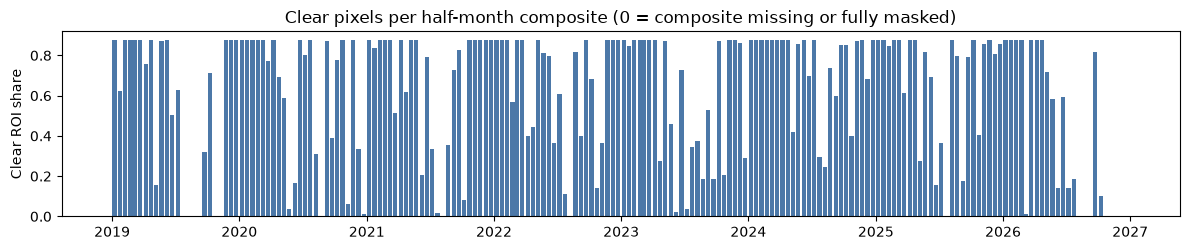

In [3]:
SLOTS = [(year, month, half) for year in YEARS for month in range(1, 13) for half in (1, 2)]
SLOT_DATE = pd.to_datetime([f"{y}-{m:02d}-{8 if h == 1 else 23}" for y, m, h in SLOTS])
SLOT_DOY = SLOT_DATE.dayofyear.to_numpy().astype(float)
slot_files = {i: IMAGERY_ROOT / str(y) / f"Sentinel2_CSPlus_{y}_{m:02d}_H{h}.tif" for i, (y, m, h) in enumerate(SLOTS)}
available = {i: path for i, path in slot_files.items() if path.is_file()}
print(f"{len(available)} of {len(SLOTS)} half-month slots have a composite")

roi_geometry = kml.loc[kml["name"] == "Region of Interest", "geometry"].iloc[0]
with rasterio.open(next(iter(available.values()))) as reference:
    GRID_CRS, GRID_TRANSFORM, GRID_SHAPE = reference.crs, reference.transform, reference.shape
    to_grid = Transformer.from_crs("EPSG:4326", GRID_CRS, always_xy=True)
    kml["grid_geometry"] = [shapely_transform(g, lambda xy: np.column_stack(to_grid.transform(xy[:, 0], xy[:, 1])))
                            for g in kml["geometry"]]
    roi_grid = kml.loc[kml["name"] == "Region of Interest", "grid_geometry"].iloc[0]
    window = from_bounds(*roi_grid.bounds, transform=GRID_TRANSFORM).round_offsets().round_lengths()
    window = window.intersection(Window(0, 0, GRID_SHAPE[1], GRID_SHAPE[0]))
    WINDOW_TRANSFORM = rasterio.windows.transform(window, GRID_TRANSFORM)
H, W = int(window.height), int(window.width)

cube_path = OUTPUT / "roi_cube.npz"
signature = json.loads(json.dumps(["nodata_masked_v2"] + sorted((str(p), p.stat().st_size) for p in available.values())))  # lists, as stored
if cube_path.is_file() and json.loads(str(np.load(cube_path)["signature"])) == signature:  # notebooks 09 and 10 reuse this cache
    cube = np.load(cube_path)["cube"]
    print("ROI cube loaded from cache:", cube_path)
else:
    cube = np.full((len(SLOTS), len(BANDS), H, W), np.nan, dtype=np.float32)
    for index, path in available.items():
        with rasterio.open(path) as source:
            if source.crs != GRID_CRS or source.transform != GRID_TRANSFORM or list(source.descriptions) != BANDS:
                raise ValueError(f"{path.name} is on a different grid or band order; reproject before use.")
            values = source.read(window=window).astype(np.float32)
            nodata = source.nodata if source.nodata is not None else -9999.0
            values[(values == nodata) | (values <= 0)] = np.nan   # some files use -9999, others NaN
            cube[index] = values / 10000.0
    np.savez_compressed(cube_path, cube=cube, signature=json.dumps(signature))


def add_indices(bands):
    """bands: (..., 5) reflectance in BANDS order -> (..., 8) with NDVI, NDRE, NDMI."""
    b4, b5, b8, b11 = bands[..., 1], bands[..., 2], bands[..., 3], bands[..., 4]
    return np.concatenate([bands, np.stack([(b8 - b4) / (b8 + b4), (b8 - b5) / (b8 + b5), (b8 - b11) / (b8 + b11)], -1)], -1)


def raster_mask(geometry, erode=0.0):
    shape = geometry.buffer(-erode) if erode else geometry
    if shape.is_empty:
        return np.zeros((H, W), bool)
    return geometry_mask([mapping(shape)], out_shape=(H, W), transform=WINDOW_TRANSFORM, invert=True)


roi_mask = raster_mask(roi_grid)
valid_share = np.array([np.isfinite(cube[t, 3][roi_mask]).mean() for t in range(len(SLOTS))])
print(f"ROI: {roi_mask.sum():,} pixels ({H}x{W} grid); mean clear share per slot {valid_share.mean():.2f}")
figure, axis = plt.subplots(figsize=(12, 2.6))
axis.bar(SLOT_DATE, valid_share, width=12, color="#4C78A8")
axis.set_ylabel("Clear ROI share")
axis.set_title("Clear pixels per half-month composite (0 = composite missing or fully masked)")
figure.tight_layout()
figure.savefig(FIGURES / "composite_coverage.png", dpi=150)
plt.show()

## 3. Windows, features and weak labels

Pixels:
- Label pixels are the KML polygon interiors after a 10 m inward buffer.
- Non-crop samples come from NAMRIA's Existing Land Use Map of Benguet (ELUM 2023), which was delineated from high-resolution imagery (Google Satellite 2015-2023), LGU maps and a 2023 ground validation survey, so it does not depend on the Sentinel-2 features. Every class except Crops is used, grouped into forest (production and protection forest, national park, and General Production Agriculture, which the ELUM metadata says marks closed forest on alienable land), built-up (residential, institutional, commercial, tourism, parks), road, pasture and water. Polygons are shrunk by 5 m (half a pixel, so small houses still keep a pixel), pixels within 10 m of a KML polygon are dropped, and up to 150 pixels are sampled per type, grouped in 300 m blocks. The land-use map is a single 2023 snapshot applied to all years, like the calendars.
- The v1 NDVI-rule anchors (always green: NDVI 10th percentile > 0.55 and median > 0.7; always bare: 90th percentile < 0.3) are still sampled, but only to show in section 4 how a model trained on them does on the land-use samples.
- The unlabeled pool is a 30 m thinned sample of the rest of the ROI, at least 10 m from the label polygons (this includes Area 1, Area 4 and Polygon 3).

A window is 6 half-month composites (3 months), starting every month. It needs at least 4 clear composites; missing ones are interpolated. Features are the 6 x 8 band and index values, phenology statistics for each index (min, max, amplitude, peak position, green-up and senescence slopes, mean, sd), the B11 change, and NDRE and NDMI at the NDVI peak. The window month is left out of the features because the labels are based on months. The number of clear composites is also left out: cloud cover follows the season (May-August is mostly masked), so it would tell the model roughly which months it is looking at. It is only used as the quality filter above. Section 4 shows the effect of adding it back.

A window is labeled when the calendar prior for its area and months is at least 0.6, and that prior is used as its weight. Windows that run from 2023 into 2024 are dropped so that training and test years do not overlap.

,polygons,hectares_in_roi,eligible_pixels,sampled_pixels
type,,,,
built_up,182,18.662,794,150
forest,32,82.790,5131,150
pasture,2,8.666,764,150
road,1,5.631,0,0
water,1,1.290,7,7


role            anchor  label                          pool                        rule_anchor
area   non_crop_anchor Area 2 Area 3 Area 5   B1  B2 Area 1 Area 4 Polygon 3   ROI rule_anchor
pixels             457    442     25     28  312  52     66      2        54  2378         169

Windows kept: 262,824 (clear >= 4 of 6); labeled 63,981; pool 161,605


split                        test  train
label      group                        
cabbage    Area 2            2081   2722
           Area 3             710   1066
           B1                1560   2808
carrot     Area 2            1768   3453
           B1                3252   5712
non_crop   landuse_built_up  3832   6255
           landuse_forest    3546   4967
           landuse_pasture   2991   4787
           landuse_water      175    217
other_crop Area 5             783   1108
           B2                1405   2198
potato     Area 2            2492   4093

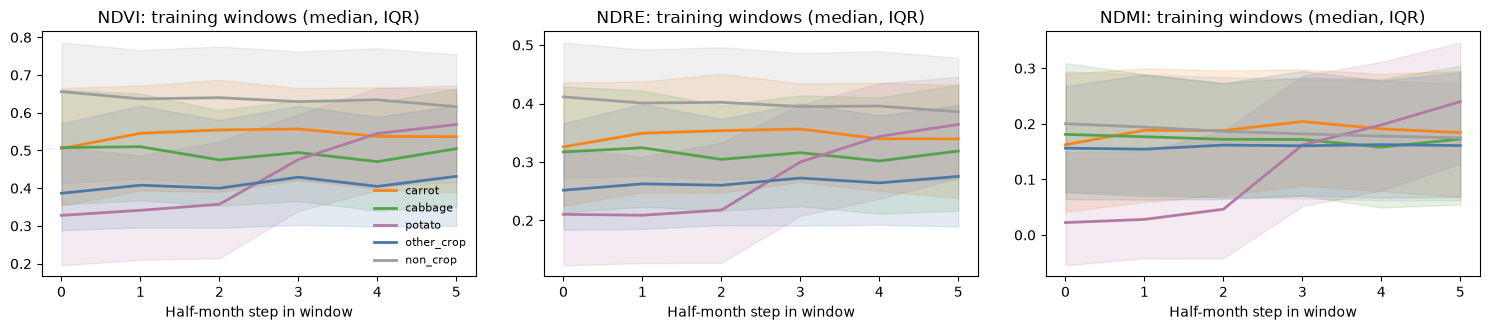

In [4]:
polygons = kml[~kml["name"].isin(["Atok", "Region of Interest"])].set_index("name")
interiors = {name: raster_mask(geom, erode=10) & roi_mask for name, geom in polygons["grid_geometry"].items()}
any_polygon_buffer = np.zeros((H, W), bool)
for geom in polygons["grid_geometry"]:
    any_polygon_buffer |= raster_mask(geom.buffer(10))
label_buffer = np.zeros((H, W), bool)
for name in LABEL_AREAS:
    label_buffer |= raster_mask(polygons.loc[name, "grid_geometry"].buffer(10))
rows_grid, cols_grid = np.indices((H, W))
thinned = (rows_grid % 3 == 0) & (cols_grid % 3 == 0) & roi_mask

ndvi_all = add_indices(np.moveaxis(cube, 1, -1))[..., 5]  # (T, H, W)
ndvi_p10, ndvi_med, ndvi_p90 = (np.nanpercentile(ndvi_all, q, axis=0) for q in (10, 50, 90))
clear_count = np.isfinite(ndvi_all).sum(0)
forest_rule = (ndvi_p10 > 0.55) & (ndvi_med > 0.7)
bare_rule = ndvi_p90 < 0.3
anchor_candidates = thinned & ~any_polygon_buffer & (clear_count >= 60)
rng = np.random.default_rng(SEED)


def sample_pixels(mask, count):
    rr, cc = np.nonzero(mask)
    pick = rng.choice(len(rr), min(count, len(rr)), replace=False) if len(rr) else np.array([], int)
    return rr[pick], cc[pick]


pixel_frames = []
for name in LABEL_AREAS:
    rr, cc = np.nonzero(interiors[name])
    pixel_frames.append(pd.DataFrame({"row": rr, "col": cc, "group": name, "parcel": name, "role": "label"}))
LANDUSE_KINDS = {  # ELUM 2023 sub-class -> non-crop type; Crops is not used
    "General Production Forest": "forest", "General Protection Forest": "forest", "National Park": "forest",
    "General Production Agriculture": "forest",  # closed forest on alienable land (ELUM metadata)
    "Residential": "built_up", "General Institutional": "built_up", "Commercial": "built_up", "General Tourism": "built_up",
    "Parks and Recreation": "built_up", "Road Network": "road", "Pasture": "pasture", "Rivers": "water"}
landuse = gpd.read_file(LANDUSE_PATH, bbox=gpd.GeoSeries([roi_grid], crs=GRID_CRS), engine="pyogrio").to_crs(GRID_CRS)
landuse = landuse[landuse.intersects(roi_grid)]
unmapped = landuse.loc[~landuse["sub_elu"].isin(LANDUSE_KINDS) & (landuse["sub_elu"] != "Crops"), "sub_elu"].unique()
if len(unmapped):
    print("Land-use classes in the ROI not used as non-crop:", sorted(unmapped))
landuse_rows = []
for kind, shapes in landuse.assign(kind=landuse["sub_elu"].map(LANDUSE_KINDS)).dropna(subset=["kind"]).groupby("kind"):
    available_mask = raster_mask(union_all(shapes.geometry.to_numpy()), erode=5) & roi_mask & ~any_polygon_buffer & (clear_count >= 60)
    rr, cc = sample_pixels(available_mask, 150)
    landuse_rows.append({"type": kind, "polygons": len(shapes), "hectares_in_roi": shapes.intersection(roi_grid).area.sum() / 1e4,
                         "eligible_pixels": int(available_mask.sum()), "sampled_pixels": len(rr)})
    pixel_frames.append(pd.DataFrame({"row": rr, "col": cc, "group": [f"landuse_{kind}_{r // 30}_{c // 30}" for r, c in zip(rr, cc)],
                                      "parcel": f"landuse_{kind}", "role": "anchor", "landuse": kind}))
display(pd.DataFrame(landuse_rows).set_index("type"))
for kind, rule in (("forest", forest_rule), ("bare", bare_rule)):  # v1 anchors, only for the section 4 comparison
    rr, cc = sample_pixels(anchor_candidates & rule, 150)
    pixel_frames.append(pd.DataFrame({"row": rr, "col": cc, "group": [f"rule_{kind}_{r // 30}_{c // 30}" for r, c in zip(rr, cc)],
                                      "parcel": f"rule_{kind}", "role": "rule_anchor", "landuse": f"rule_{kind}"}))
anchor_mask = np.zeros((H, W), bool)
for frame in pixel_frames[len(LABEL_AREAS):]:
    anchor_mask[frame["row"], frame["col"]] = True
rr, cc = sample_pixels(thinned & ~label_buffer & ~anchor_mask & (clear_count >= 60), 2500)
pixel_frames.append(pd.DataFrame({"row": rr, "col": cc, "group": "pool", "parcel": [f"pool_{r}_{c}" for r, c in zip(rr, cc)], "role": "pool"}))
pixels = pd.concat(pixel_frames, ignore_index=True)
pixels["pixel_id"] = np.arange(len(pixels))
pixels["area"] = "ROI"
for name, mask in interiors.items():
    inside = mask[pixels["row"], pixels["col"]]
    pixels.loc[inside, "area"] = name
pixels.loc[pixels["role"] == "anchor", "area"] = "non_crop_anchor"
pixels.loc[pixels["role"] == "rule_anchor", "area"] = "rule_anchor"
display(pixels.groupby(["role", "area"]).size().rename("pixels").to_frame().T)


def fill_window_gaps(values):
    """values: (N, L, V) with NaN gaps along L -> linearly interpolated, edge gaps take the nearest value."""
    valid = np.isfinite(values).all(-1)
    steps = np.arange(values.shape[1])
    previous = np.maximum.accumulate(np.where(valid, steps, -1), axis=1)
    following = np.flip(np.minimum.accumulate(np.flip(np.where(valid, steps, 10**6), 1), axis=1), 1)
    prev_ok, next_ok = previous >= 0, following < 10**6
    p, n = np.clip(previous, 0, None), np.clip(following, None, values.shape[1] - 1)
    take = lambda idx: np.take_along_axis(values, idx[..., None].repeat(values.shape[2], -1), 1)
    vp, vn = take(p), take(n)
    span = np.where((n - p) > 0, n - p, 1)[..., None]
    interpolated = vp + (vn - vp) * ((steps[None, :] - p)[..., None] / span)
    filled = np.where((prev_ok & next_ok)[..., None], interpolated, np.where(prev_ok[..., None], vp, vn))
    return np.where(valid[..., None], values, filled)


WINDOW_STARTS = [i for i, (y, m, h) in enumerate(SLOTS) if h == 1 and i + WINDOW <= len(SLOTS)]


def extract_windows(rows, cols, starts=WINDOW_STARTS):
    metas, arrays = [], []
    for start in starts:
        values = add_indices(np.moveaxis(cube[start:start + WINDOW][:, :, rows, cols], 1, -1).transpose(1, 0, 2))  # (N, L, 8)
        clear = np.isfinite(values).all(-1).sum(1)
        keep = clear >= MIN_VALID
        if not keep.any():
            continue
        arrays.append(fill_window_gaps(values[keep]))
        year, month, _ = SLOTS[start]
        end_year = SLOTS[start + WINDOW - 1][0]
        metas.append(pd.DataFrame({"pixel_index": np.nonzero(keep)[0], "start_slot": start, "year": year,
                                   "month": month, "end_year": end_year, "clear": clear[keep]}))
    return pd.concat(metas, ignore_index=True), np.concatenate(arrays)


def window_features(meta, arrays):
    features = {f"t{step}_{var}": arrays[:, step, v] for step in range(WINDOW) for v, var in enumerate(VARS)}
    for name in INDICES:
        values = arrays[:, :, VARS.index(name)]
        peak = values.argmax(1)
        maximum, minimum = values.max(1), values.min(1)
        features.update({
            f"{name}_min": minimum, f"{name}_max": maximum, f"{name}_amp": maximum - minimum,
            f"{name}_peak_step": peak, f"{name}_mean": values.mean(1), f"{name}_sd": values.std(1),
            f"{name}_greenup": (maximum - values[:, 0]) / np.maximum(peak, 1),
            f"{name}_senescence": (maximum - values[:, -1]) / np.maximum(WINDOW - 1 - peak, 1),
        })
    ndvi_peak = arrays[:, :, VARS.index("NDVI")].argmax(1)
    for name in ("NDRE", "NDMI"):
        features[f"{name}_at_ndvi_peak"] = arrays[np.arange(len(arrays)), ndvi_peak, VARS.index(name)]
    features["B11_change"] = arrays[:, -1, VARS.index("B11")] - arrays[:, 0, VARS.index("B11")]
    return pd.DataFrame(features)


meta, window_arrays = extract_windows(pixels["row"].to_numpy(), pixels["col"].to_numpy())
meta = meta.join(pixels.reset_index(drop=True), on="pixel_index")
FEATURES = window_features(meta, window_arrays)
FEATURE_COLUMNS = list(FEATURES.columns)
windows = pd.concat([meta, FEATURES], axis=1)
windows["doy"] = [SLOT_DOY[s:s + WINDOW] for s in windows["start_slot"]]

priors = np.array([window_prior(area_priors[a], m) if a in area_priors else np.full(5, np.nan)
                   for a, m in zip(windows["area"], windows["month"])])
windows["label"], windows["label_weight"] = None, 0.0
is_label = windows["role"].eq("label").to_numpy()
windows.loc[is_label, "label"] = np.asarray(CLASSES)[priors[is_label].argmax(1)]
windows.loc[is_label, "label_weight"] = priors[is_label].max(1)
windows.loc[is_label & (np.nan_to_num(priors.max(1)) < 0.6), "label"] = None
windows.loc[windows["role"].eq("anchor"), ["label", "label_weight"]] = ["non_crop", 0.5]
windows["K"] = list(np.array([window_prior(regional_prior, m) for m in windows["month"]]))
windows["split"] = np.where(windows["end_year"].isin(TRAIN_YEARS), "train",
                            np.where(windows["year"].isin(TEST_YEARS), "test", "buffer"))
labeled = windows[windows["label"].notna() & windows["split"].ne("buffer")].reset_index(drop=True)
pool = windows[windows["role"].eq("pool") & windows["split"].ne("buffer")].reset_index(drop=True)
print(f"Windows kept: {len(windows):,} (clear >= {MIN_VALID} of {WINDOW}); labeled {len(labeled):,}; pool {len(pool):,}")
summary = labeled.assign(group=np.where(labeled["role"] == "anchor", "landuse_" + labeled["landuse"].astype(str), labeled["group"]))
display(summary.pivot_table(index=["label", "group"], columns="split", values="pixel_id", aggfunc="size", fill_value=0))

figure, axes = plt.subplots(1, 3, figsize=(15, 3.4), sharex=True)
for axis, name in zip(axes, INDICES):
    for crop in CLASSES:
        rows = labeled[(labeled["label"] == crop) & (labeled["split"] == "train")]
        if len(rows):
            curves = rows[[f"t{s}_{name}" for s in range(WINDOW)]].to_numpy()
            axis.plot(range(WINDOW), np.median(curves, 0), color=COLORS[crop], lw=2, label=crop)
            axis.fill_between(range(WINDOW), *np.percentile(curves, [25, 75], 0), color=COLORS[crop], alpha=0.15)
    axis.set_title(f"{name}: training windows (median, IQR)")
    axis.set_xlabel("Half-month step in window")
axes[0].legend(frameon=False, fontsize=8)
figure.tight_layout()
figure.savefig(FIGURES / "label_window_profiles.png", dpi=150)
plt.show()

## 4. Experiment A: supervised baseline

Train on 2019-2023, test on 2024-2026. Each class has the same total weight, split equally across its groups (polygons or anchor blocks). Scores are reported per pixel window and per parcel window (mean probability over a polygon in one window, with forest and bare anchors as one parcel each). The parcel scores are more meaningful since pixels in the same small field are very similar.

Models:
- RF: 500 trees, sqrt features, min leaf 2
- Gradient boosting (HistGradientBoosting, since XGBoost is not installed)
- Two-stage RF: crop vs non-crop first, then crop type; P(class) = P(crop) x P(class | crop)
- Month-only RF: uses only the window start month, to see how much the calendar alone explains
- RF + clear count: the RF with the number of clear composites added back (it was a feature in v1), to see how much of the score came from the cloud season

Non-crop recall is also reported per land-use type, because houses, roads and pasture are much harder than forest. The last table compares this model with one trained on the v1 NDVI-rule anchors instead: v1 chose its non-crop examples with an NDVI rule while the features include NDVI min, max and mean, so its non-crop score was close to automatic. Here both models are scored on the same land-use samples.

The leave-one-polygon-out check holds out each polygon in turn, for classes that occur in at least two polygons.

In [5]:
def balanced_weights(frame, base="label_weight", label="label"):
    weights = frame[base].to_numpy(dtype=float).copy()
    for crop, rows in frame.groupby(label):
        groups = rows["group"].unique()
        for group in groups:
            mask = ((frame[label] == crop) & (frame["group"] == group)).to_numpy()
            weights[mask] = weights[mask] / weights[mask].sum() / len(groups)
    return weights * len(weights) / weights.sum()


def forest(**overrides):
    return RandomForestClassifier(**{"n_estimators": 500, "max_features": "sqrt", "min_samples_leaf": 2,
                                     "n_jobs": -1, "random_state": SEED, **overrides})


def aligned_proba(model, X, classes=CLASSES):
    proba = model.predict_proba(X)
    out = np.zeros((len(X), len(classes)))
    for index, name in enumerate(model.classes_):
        out[:, classes.index(name)] = proba[:, index]
    return out


class TwoStage:
    def fit(self, X, y, sample_weight):
        y = np.asarray(y)
        self.stage1 = forest().fit(X, np.where(y == "non_crop", "non_crop", "crop"), sample_weight=sample_weight)
        crop = y != "non_crop"
        self.stage2 = forest().fit(X[crop], y[crop], sample_weight=sample_weight[crop])
        self.classes_ = np.asarray(CLASSES)
        return self

    def predict_proba(self, X):
        p1 = aligned_proba(self.stage1, X, ["crop", "non_crop"])
        p2 = aligned_proba(self.stage2, X, CROP_CLASSES)
        return np.hstack([p2 * p1[:, [0]], p1[:, [1]]])


def fit_model(kind, frame, columns=None, weights=None, label="label"):
    columns = columns or FEATURE_COLUMNS
    weights = balanced_weights(frame, label=label) if weights is None else weights
    X, y = frame[columns].to_numpy(), frame[label].to_numpy()
    model = {"rf_flat": forest, "gradient_boosting": lambda: HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, random_state=SEED), "rf_two_stage": TwoStage}[kind]()
    return model.fit(X, y, sample_weight=weights)


def expected_calibration_error(proba, truth, bins=10):
    confidence, correct = proba.max(1), (np.asarray(CLASSES)[proba.argmax(1)] == truth)
    edges = np.linspace(0, 1, bins + 1)
    return float(sum(abs(correct[m].mean() - confidence[m].mean()) * m.mean()
                     for lo, hi in zip(edges[:-1], edges[1:]) for m in [(confidence > lo) & (confidence <= hi)] if m.any()))


def score(frame, proba, label="label"):
    truth = frame[label].to_numpy()
    prediction = np.asarray(CLASSES)[proba.argmax(1)]
    present = [c for c in CLASSES if c in set(truth)]
    precision, recall, f1, support = precision_recall_fscore_support(truth, prediction, labels=CLASSES, zero_division=0)
    parcel = (pd.DataFrame(proba, columns=CLASSES).assign(parcel=frame["parcel"].to_numpy(), slot=frame["start_slot"].to_numpy(), truth=truth)
              .groupby(["parcel", "slot", "truth"])[CLASSES].mean().reset_index())
    parcel_prediction = parcel[CLASSES].to_numpy().argmax(1)
    return {
        "pixel_windows": len(frame), "parcel_windows": len(parcel),
        "macro_f1": f1_score(truth, prediction, labels=present, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(truth, prediction),
        "kappa": cohen_kappa_score(truth, prediction),
        "parcel_macro_f1": f1_score(parcel["truth"], np.asarray(CLASSES)[parcel_prediction], labels=present, average="macro", zero_division=0),
        "pr_auc_macro": np.mean([average_precision_score(truth == c, proba[:, CLASSES.index(c)]) for c in present]),
        "ece": expected_calibration_error(proba, truth),
        **{f"precision_{c}": precision[i] for i, c in enumerate(CLASSES)},
        **{f"recall_{c}": recall[i] for i, c in enumerate(CLASSES)},
        "confusion": confusion_matrix(truth, prediction, labels=CLASSES).tolist(),
    }


train, test = labeled[labeled["split"] == "train"].reset_index(drop=True), labeled[labeled["split"] == "test"].reset_index(drop=True)
results, probabilities = {}, {}
for kind in ("rf_flat", "gradient_boosting", "rf_two_stage"):
    model = fit_model(kind, train)
    probabilities[f"A_{kind}"] = aligned_proba(model, test[FEATURE_COLUMNS].to_numpy()) if kind != "rf_two_stage" else model.predict_proba(test[FEATURE_COLUMNS].to_numpy())
    results[f"A_{kind}"] = score(test, probabilities[f"A_{kind}"])
# Contrast: the v1 non-crop anchors (NDVI rule) in place of the land-use samples, both scored on the same windows
rule_windows = windows[windows["role"].eq("rule_anchor") & windows["split"].ne("buffer")].assign(label="non_crop", label_weight=0.5)
rule_model = fit_model("rf_flat", pd.concat([train[train["label"] != "non_crop"], rule_windows[rule_windows["split"] == "train"]], ignore_index=True))
landuse_test, rule_test = test[test["label"] == "non_crop"], rule_windows[rule_windows["split"] == "test"]
month_columns = ["month_sin", "month_cos"]
for frame in (train, test):
    frame["month_sin"], frame["month_cos"] = np.sin(2 * np.pi * frame["month"] / 12), np.cos(2 * np.pi * frame["month"] / 12)
month_model = fit_model("rf_flat", train, columns=month_columns)
probabilities["A_month_only"] = aligned_proba(month_model, test[month_columns].to_numpy())
results["A_month_only"] = score(test, probabilities["A_month_only"])
baseline_model = fit_model("rf_flat", train)
clear_columns = FEATURE_COLUMNS + ["clear"]  # ablation only; `clear` is the clear-composite count per window
probabilities["A_rf_with_clear_count"] = aligned_proba(fit_model("rf_flat", train, columns=clear_columns), test[clear_columns].to_numpy())
results["A_rf_with_clear_count"] = score(test, probabilities["A_rf_with_clear_count"])
print(f"Macro-F1 without / with the clear-composite count: {results['A_rf_flat']['macro_f1']:.3f} / "
      f"{results['A_rf_with_clear_count']['macro_f1']:.3f}")

non_crop_contrast = {}
for name, model in (("trained on land-use samples", baseline_model), ("trained on NDVI-rule anchors (v1)", rule_model)):
    def called_non_crop(frame):
        return pd.Series(np.asarray(CLASSES)[aligned_proba(model, frame[FEATURE_COLUMNS].to_numpy()).argmax(1)] == "non_crop", index=frame.index)
    landuse_hits = called_non_crop(landuse_test)
    non_crop_contrast[name] = {**landuse_hits.groupby(landuse_test["landuse"]).mean().to_dict(), "all land-use non-crop": landuse_hits.mean(),
                               "NDVI-rule anchors": called_non_crop(rule_test).mean(),
                               "crop windows called non-crop": called_non_crop(test[test["label"] != "non_crop"]).mean()}
non_crop_contrast = pd.DataFrame(non_crop_contrast)
non_crop_contrast.to_csv(OUTPUT / "non_crop_recall_by_landuse.csv")

metric_columns = ["pixel_windows", "parcel_windows", "macro_f1", "parcel_macro_f1", "balanced_accuracy", "kappa", "pr_auc_macro", "ece"]
display(pd.DataFrame(results).T[metric_columns])
display(pd.DataFrame(results).T[[f"recall_{c}" for c in CLASSES] + [f"precision_{c}" for c in CLASSES]])

lopo_records = []
for crop in CLASSES:
    groups = labeled.loc[labeled["label"] == crop, "group"].unique()
    holdouts = groups if crop != "non_crop" else []
    if crop == "non_crop":  # anchor blocks: hold out two random halves, each with forest and bare blocks
        shuffled = list(np.random.default_rng(SEED).permutation(groups))
        holdouts = [shuffled[::2], shuffled[1::2]]
    if len(groups) < 2:
        lopo_records.append({"class": crop, "held_out": ", ".join(groups), "status": "single group: not testable"})
        continue
    for held in holdouts:
        held = [held] if isinstance(held, str) else held
        if not held:
            continue
        fit_rows = labeled[~labeled["group"].isin(held)]
        if crop not in set(fit_rows["label"]):
            lopo_records.append({"class": crop, "held_out": "+".join(held)[:40], "status": "class absent after holdout"})
            continue
        evaluation = labeled[labeled["group"].isin(held) & (labeled["label"] == crop)]
        model = fit_model("rf_flat", fit_rows.reset_index(drop=True))
        proba = aligned_proba(model, evaluation[FEATURE_COLUMNS].to_numpy())
        predicted = np.asarray(CLASSES)[proba.argmax(1)]
        lopo_records.append({"class": crop, "held_out": "+".join(held)[:40] if len(held) < 3 else f"{len(held)} {crop} anchor blocks",
                             "status": "tested", "windows": len(evaluation), "recall": float((predicted == crop).mean()),
                             "most_common_prediction": pd.Series(predicted).mode()[0]})
        if crop == "non_crop":  # the same held-out blocks, split by land-use type
            for kind, part in pd.DataFrame({"kind": evaluation["landuse"].to_numpy(), "predicted": predicted}).groupby("kind"):
                lopo_records.append({"class": f"non_crop: {kind}", "held_out": f"{len(held)} {crop} anchor blocks", "status": "tested",
                                     "windows": len(part), "recall": float((part["predicted"] == crop).mean()),
                                     "most_common_prediction": part["predicted"].mode()[0]})
lopo = pd.DataFrame(lopo_records)
lopo.to_csv(OUTPUT / "leave_one_polygon_out.csv", index=False)
display(lopo)
print("Share of test windows called non-crop (land-use types, the v1 rule anchors, and crop windows):")
display(non_crop_contrast.style.format("{:.0%}"))

Macro-F1 without / with the clear-composite count: 0.592 / 0.592


,pixel_windows,parcel_windows,macro_f1,parcel_macro_f1,balanced_accuracy,kappa,pr_auc_macro,ece
A_rf_flat,24595,230,0.592,0.654,0.587,0.536,0.627,0.103
A_gradient_boosting,24595,230,0.56,0.66,0.558,0.507,0.61,0.14
A_rf_two_stage,24595,230,0.581,0.632,0.577,0.522,0.621,0.073
A_month_only,24595,230,0.371,0.219,0.492,0.256,0.363,0.143
A_rf_with_clear_count,24595,230,0.592,0.655,0.585,0.535,0.627,0.106


,recall_carrot,recall_cabbage,recall_potato,recall_other_crop,recall_non_crop,precision_carrot,precision_cabbage,precision_potato,precision_other_crop,precision_non_crop
A_rf_flat,0.513,0.424,0.61,0.496,0.895,0.542,0.537,0.613,0.506,0.801
A_gradient_boosting,0.448,0.423,0.477,0.542,0.903,0.553,0.519,0.6,0.413,0.784
A_rf_two_stage,0.479,0.396,0.607,0.495,0.906,0.558,0.524,0.605,0.499,0.775
A_month_only,0.441,0.745,1.0,0.146,0.13,0.387,0.437,0.35,0.184,0.523
A_rf_with_clear_count,0.521,0.423,0.583,0.5,0.898,0.536,0.539,0.634,0.511,0.798


,class,held_out,status,windows,recall,most_common_prediction
0,carrot,B1,tested,8964.0,0.057,potato
1,carrot,Area 2,tested,5221.0,0.071,cabbage
2,cabbage,B1,tested,4368.0,0.206,carrot
3,cabbage,Area 3,tested,1776.0,0.292,carrot
4,cabbage,Area 2,tested,4803.0,0.263,non_crop
5,potato,Area 2,single group: not testable,NaN,NaN,NaN
6,other_crop,B2,tested,3603.0,0.007,cabbage
7,other_crop,Area 5,tested,1891.0,0.003,non_crop
8,non_crop,34 non_crop anchor blocks,tested,16041.0,0.898,non_crop
9,non_crop: built_up,34 non_crop anchor blocks,tested,3573.0,0.726,non_crop


Share of test windows called non-crop (land-use types, the v1 rule anchors, and crop windows):


,trained on land-use samples,trained on NDVI-rule anchors (v1)
built_up,80%,28%
forest,92%,79%
pasture,98%,86%
water,95%,20%
all land-use non-crop,90%,61%
NDVI-rule anchors,98%,96%
crop windows called non-crop,17%,3%


## 5. Experiment B: clustering

(i) Annual Fourier features. NDVI, NDRE and NDMI for each pixel-year (at least 14 clear half-months) are fitted with 2, 3 and 4 harmonics, and the number of harmonics is picked by held-out reconstruction error (every fourth point left out). A GMM is then fitted on the coefficients, with K in {8, 10, 12, 15} and diagonal or full covariance chosen by BIC. Stability is the adjusted Rand index (ARI) between three seeds. In rotation areas one pixel-year contains several crops, so these clusters describe cropping patterns rather than crops.

(ii) Window clusters. A GMM on PCA(20) of the window features (training years, labeled and pool). P(class | cluster) comes from the training labels with Laplace smoothing, and the cluster affinity of a window is $C = \sum_k P(k \mid x)\,P(\text{class} \mid k)$. This is also scored as a classifier on the test years.

In [6]:
def fourier_design(doy, harmonics):
    angle = 2 * np.pi * doy / 365.25
    return np.column_stack([np.ones_like(angle)] + [f(k * angle) for k in range(1, harmonics + 1) for f in (np.cos, np.sin)])


pixel_series = add_indices(np.moveaxis(cube[:, :, pixels["row"].to_numpy(), pixels["col"].to_numpy()], 1, -1).transpose(1, 0, 2))
slot_year = np.array([y for y, _, _ in SLOTS])
cv_errors = {h: [] for h in (2, 3, 4)}
annual_rows = []
for year in YEARS:
    slots = np.nonzero(slot_year == year)[0]
    for p in range(len(pixels)):
        values = pixel_series[p, slots][:, [5, 6, 7]]
        clear = np.isfinite(values).all(axis=1)
        if clear.sum() < 14:
            continue
        doy, y = SLOT_DOY[slots][clear], values[clear]
        holdout = np.arange(clear.sum()) % 4 == 0
        for h in cv_errors:
            beta, *_ = np.linalg.lstsq(fourier_design(doy[~holdout], h), y[~holdout], rcond=None)
            cv_errors[h].append(np.sqrt(np.mean((fourier_design(doy[holdout], h) @ beta - y[holdout]) ** 2)))
        annual_rows.append((p, year, doy, y))
mean_error = {h: float(np.mean(e)) for h, e in cv_errors.items()}
HARMONICS = 2
for h in (3, 4):
    if mean_error[h] < mean_error[HARMONICS] * 0.95:
        HARMONICS = h
print("Held-out Fourier RMSE by harmonics:", {h: round(e, 4) for h, e in mean_error.items()}, "-> using", HARMONICS)
coefficients = np.array([np.linalg.lstsq(fourier_design(doy, HARMONICS), y, rcond=None)[0].T.ravel() for _, _, doy, y in annual_rows])
annual = pd.DataFrame({"pixel_id": [r[0] for r in annual_rows], "year": [r[1] for r in annual_rows]}).join(pixels[["area", "role"]], on="pixel_id")
Z = StandardScaler().fit_transform(coefficients)
bic = {(k, cov): GaussianMixture(k, covariance_type=cov, random_state=SEED, n_init=3, reg_covar=1e-4).fit(Z).bic(Z)
       for k in (8, 10, 12, 15) for cov in ("diag", "full")}
best_k, best_cov = min(bic, key=bic.get)
labels_by_seed = [GaussianMixture(best_k, covariance_type=best_cov, random_state=s, n_init=3, reg_covar=1e-4).fit_predict(Z) for s in (0, 1, 2)]
stability = np.mean([adjusted_rand_score(labels_by_seed[i], labels_by_seed[j]) for i, j in ((0, 1), (0, 2), (1, 2))])
annual["regime"] = labels_by_seed[0]
print(f"Annual GMM: K={best_k}, covariance={best_cov}, seed stability ARI={stability:.2f}")
display(pd.DataFrame(bic, index=["BIC"]).T.unstack())
composition = pd.crosstab(annual["area"], annual["regime"], normalize="index")
display(composition.style.format("{:.0%}").background_gradient(axis=None, cmap="Blues"))

window_scaler = StandardScaler().fit(pd.concat([train, pool[pool["split"] == "train"]])[FEATURE_COLUMNS])


def fit_window_clusters(train_labeled, train_pool, k=None):
    fit_frame = pd.concat([train_labeled[FEATURE_COLUMNS], train_pool[FEATURE_COLUMNS]])
    fit_frame = fit_frame.sample(min(len(fit_frame), 40000), random_state=SEED)
    pca = PCA(20, random_state=SEED)
    reduced = pca.fit_transform(window_scaler.transform(fit_frame))
    if k is None:
        scores = {kk: GaussianMixture(kk, covariance_type="diag", random_state=SEED, reg_covar=1e-4).fit(reduced).bic(reduced) for kk in (8, 10, 12, 15)}
        k = min(scores, key=scores.get)
    gmm = GaussianMixture(k, covariance_type="diag", random_state=SEED, reg_covar=1e-4).fit(reduced)
    responsibility = gmm.predict_proba(pca.transform(window_scaler.transform(train_labeled[FEATURE_COLUMNS])))
    counts = np.ones((k, len(CLASSES)))  # Laplace smoothing
    weights = balanced_weights(train_labeled)
    for index, crop in enumerate(CLASSES):
        mask = (train_labeled["label"] == crop).to_numpy()
        counts[:, index] += (responsibility[mask] * weights[mask, None]).sum(0)
    class_given_cluster = counts / counts.sum(1, keepdims=True)
    return {"gmm": gmm, "pca": pca, "k": k, "class_given_cluster": class_given_cluster}


def cluster_affinity(clusters, frame):
    responsibility = clusters["gmm"].predict_proba(clusters["pca"].transform(window_scaler.transform(frame[FEATURE_COLUMNS])))
    return responsibility @ clusters["class_given_cluster"], responsibility.argmax(1)


window_clusters = fit_window_clusters(train, pool[pool["split"] == "train"])
probabilities["B_window_clusters"], _ = cluster_affinity(window_clusters, test)
results["B_window_clusters"] = score(test, probabilities["B_window_clusters"])
print(f"Window GMM: K={window_clusters['k']} (BIC)")
display(pd.DataFrame(window_clusters["class_given_cluster"], columns=CLASSES).style.format("{:.2f}").background_gradient(axis=None, cmap="Greens"))

Held-out Fourier RMSE by harmonics: {2: 0.0975, 3: 0.0974, 4: 0.1276} -> using 2


Annual GMM: K=15, covariance=full, seed stability ARI=0.42


BIC            
          diag        full
8   911676.360  439311.191
10  896356.212  436821.938
12  877934.699  433733.162
15  858669.898  430369.042

regime,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
area,,,,,,,,,,,,,,,
Area 1,8%,5%,0%,2%,5%,1%,11%,2%,10%,13%,6%,13%,13%,12%,0%
Area 2,5%,15%,0%,18%,8%,0%,1%,1%,3%,2%,16%,6%,9%,15%,0%
Area 3,0%,39%,0%,0%,1%,0%,23%,0%,0%,5%,0%,3%,14%,16%,0%
Area 4,0%,0%,0%,0%,0%,0%,0%,0%,50%,7%,0%,14%,21%,7%,0%
Area 5,39%,0%,0%,0%,0%,0%,0%,59%,0%,1%,1%,1%,0%,0%,0%
B1,2%,4%,0%,2%,2%,0%,25%,1%,8%,20%,3%,6%,15%,13%,0%
B2,0%,7%,0%,1%,1%,0%,13%,0%,41%,10%,1%,6%,12%,9%,0%
Polygon 3,7%,12%,1%,10%,3%,2%,9%,2%,7%,1%,8%,12%,12%,13%,2%
ROI,10%,4%,7%,1%,4%,7%,5%,4%,10%,5%,6%,12%,10%,10%,7%


Window GMM: K=15 (BIC)


,carrot,cabbage,potato,other_crop,non_crop
0,0.18,0.26,0.45,0.10,0.01
1,0.15,0.14,0.31,0.09,0.32
2,0.26,0.27,0.16,0.21,0.11
3,0.04,0.12,0.07,0.46,0.31
4,0.37,0.23,0.16,0.19,0.04
5,0.04,0.00,0.00,0.00,0.95
6,0.32,0.43,0.10,0.14,0.01
7,0.15,0.20,0.34,0.16,0.14
8,0.27,0.20,0.14,0.16,0.24
9,0.12,0.07,0.04,0.10,0.66


## 6. Experiment C: TWDTW matching

Prototypes are the median NDVI/NDRE/NDMI curves of the training windows for each class and start season (Dec-Feb, Mar-May, Jun-Aug, Sep-Nov), if the group has at least 30 windows. Each step keeps its day of year.

The cost of matching window step i to prototype step j is the Euclidean distance between the index values plus a logistic time penalty $1 / (1 + e^{-\alpha(\Delta t - \beta)})$, where $\Delta t$ is the day-of-year difference (Maus et al., 2016). The distance to a class is the smallest TWDTW distance to any of its prototypes. Alpha and beta are tuned with prototypes from 2019-2021 scored on 2022-2023.

,alpha,beta,inner_macro_f1
4,0.10,45,0.382
2,0.05,60,0.378
5,0.10,60,0.377
1,0.05,45,0.368
0,0.05,30,0.347
3,0.10,30,0.346


TWDTW: alpha=0.1, beta=45.0 days, 16 prototypes, temperature=1.470


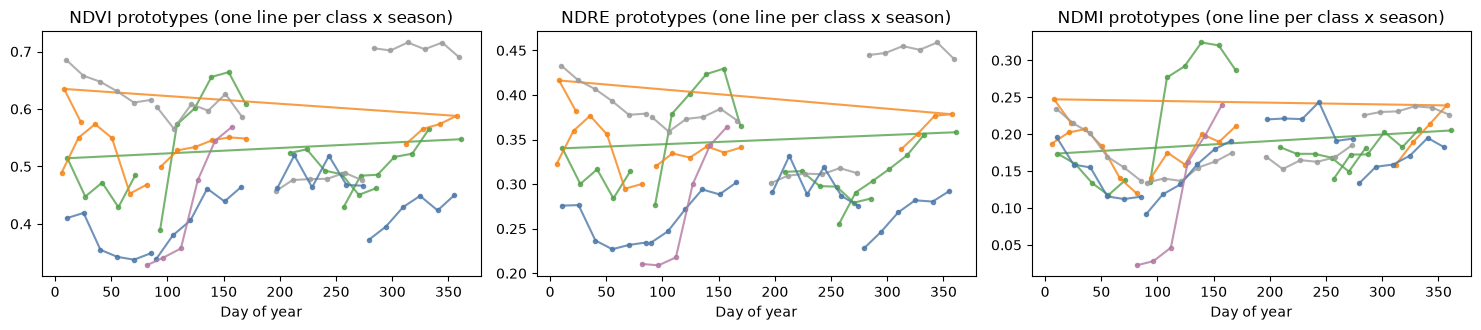

In [7]:
INDEX_POSITIONS = [VARS.index(name) for name in INDICES]
SEASON = {12: 0, 1: 0, 2: 0, 3: 1, 4: 1, 5: 1, 6: 2, 7: 2, 8: 2, 9: 3, 10: 3, 11: 3}


def trajectories(frame):
    return np.stack([frame[[f"t{s}_{name}" for s in range(WINDOW)]].to_numpy() for name in INDICES], -1)


def build_prototypes(frame, minimum=30):
    prototypes = []
    for (crop, season), rows in frame.groupby([frame["label"], frame["month"].map(SEASON)]):
        if len(rows) < minimum:
            continue
        doy = np.stack(rows["doy"].to_numpy())
        angle = np.angle(np.exp(1j * 2 * np.pi * doy / 365.25).mean(0))
        prototypes.append({"class": crop, "season": season, "curve": np.median(trajectories(rows), 0),
                           "doy": (angle % (2 * np.pi)) * 365.25 / (2 * np.pi), "n": len(rows)})
    return prototypes


def twdtw(queries, query_doy, curve, curve_doy, alpha, beta):
    distance = np.linalg.norm(queries[:, :, None, :] - curve[None, None, :, :], axis=-1)
    gap = np.abs(query_doy[:, :, None] - curve_doy[None, None, :])
    gap = np.minimum(gap, 365.25 - gap)
    cost = distance + 1 / (1 + np.exp(-alpha * (gap - beta)))
    n, rows, cols = cost.shape
    accumulated = np.full((n, rows + 1, cols + 1), np.inf)
    accumulated[:, 0, 0] = 0
    for i in range(1, rows + 1):
        for j in range(1, cols + 1):
            accumulated[:, i, j] = cost[:, i - 1, j - 1] + np.minimum(np.minimum(accumulated[:, i - 1, j], accumulated[:, i, j - 1]), accumulated[:, i - 1, j - 1])
    return accumulated[:, rows, cols]


def class_distances(frame, prototypes, alpha, beta):
    queries, query_doy = trajectories(frame), np.stack(frame["doy"].to_numpy())
    distances = np.full((len(frame), len(CLASSES)), np.inf)
    for prototype in prototypes:
        index = CLASSES.index(prototype["class"])
        distances[:, index] = np.minimum(distances[:, index], twdtw(queries, query_doy, prototype["curve"], prototype["doy"], alpha, beta))
    return distances


def similarity(distances, temperature):
    logits = -distances / temperature
    logits -= logits.max(1, keepdims=True)
    weights = np.exp(logits)
    return weights / weights.sum(1, keepdims=True)


inner_train, inner_validation = train[train["year"] <= 2021], train[train["year"] >= 2022]
tuning = []
for alpha in (0.05, 0.1):
    for beta in (30, 45, 60):
        distances = class_distances(inner_validation, build_prototypes(inner_train), alpha, beta)
        prediction = np.asarray(CLASSES)[distances.argmin(1)]
        tuning.append({"alpha": alpha, "beta": beta, "inner_macro_f1": f1_score(inner_validation["label"], prediction, average="macro", zero_division=0)})
tuning = pd.DataFrame(tuning).sort_values("inner_macro_f1", ascending=False)
ALPHA, BETA = tuning.iloc[0][["alpha", "beta"]]
display(tuning)
prototypes = build_prototypes(train)
train_distances = class_distances(train, prototypes, ALPHA, BETA)
TEMPERATURE = float(np.median(train_distances.min(1)))
own_distance = {c: np.percentile(train_distances[(train["label"] == c).to_numpy(), CLASSES.index(c)], 90) for c in CLASSES}
test_distances = class_distances(test, prototypes, ALPHA, BETA)
probabilities["C_twdtw"] = similarity(test_distances, TEMPERATURE)
results["C_twdtw"] = score(test, probabilities["C_twdtw"])
print(f"TWDTW: alpha={ALPHA}, beta={BETA} days, {len(prototypes)} prototypes, temperature={TEMPERATURE:.3f}")

figure, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for axis, (v, name) in zip(axes, enumerate(INDICES)):
    for prototype in prototypes:
        axis.plot(prototype["doy"], prototype["curve"][:, v], "-o", ms=3, color=COLORS[prototype["class"]], alpha=0.8)
    axis.set_title(f"{name} prototypes (one line per class x season)")
    axis.set_xlabel("Day of year")
figure.tight_layout()
figure.savefig(FIGURES / "twdtw_prototypes.png", dpi=150)
plt.show()

## 7. Experiment D: TWDTW with calendar prior

The TWDTW similarity is multiplied by the regional calendar prior K (Areas 1 and 4) and renormalized. The test labels come from the area calendars, which are a different source, but both describe the same place, so this comparison is probably optimistic.

In [8]:
test_K = np.stack(test["K"].to_numpy())
combined = probabilities["C_twdtw"] * test_K
probabilities["D_twdtw_calendar"] = combined / combined.sum(1, keepdims=True)
results["D_twdtw_calendar"] = score(test, probabilities["D_twdtw_calendar"])
display(pd.DataFrame(results).T.loc[["C_twdtw", "D_twdtw_calendar"], metric_columns])

,pixel_windows,parcel_windows,macro_f1,parcel_macro_f1,balanced_accuracy,kappa,pr_auc_macro,ece
C_twdtw,24595,230,0.449,0.389,0.48,0.313,0.462,0.114
D_twdtw_calendar,24595,230,0.277,0.264,0.335,0.202,0.459,0.108


## 8. Experiment E: pseudo-labels

Pool windows from the training years get four scores: P (baseline RF probability), T (TWDTW similarity), C (cluster affinity) and K (regional calendar prior). The fused score is E = (P + T + C + K) / 4. A window gets pseudo-label c only if:

1. c is the top class for both P and E
2. P(c) >= tau and P's margin over the second class >= m
3. its TWDTW distance to c is within the 90th percentile of the training windows of c
4. c is in the top two of K, or c is the top class of C
5. K(c) >= 0.05

Each class gets at most twice its number of training windows (and at most twice the median class), taken in order of E, with at most a third from one cluster. Pseudo-labels get half the weight of calendar labels. tau in {0.8, 0.9} and m in {0.15, 0.2}, or no pseudo-labels, are chosen on inner years (fit 2019-2021, validate 2022-2023). Then A and E are compared on 2024-2026.

In [9]:
def evidence(train_labeled, candidate_pool, clusters_k=None):
    model = fit_model("rf_flat", train_labeled)
    P = aligned_proba(model, candidate_pool[FEATURE_COLUMNS].to_numpy())
    protos = build_prototypes(train_labeled)
    train_dist = class_distances(train_labeled, protos, ALPHA, BETA)
    temperature = float(np.median(train_dist.min(1)))
    limits = {c: np.percentile(train_dist[(train_labeled["label"] == c).to_numpy(), CLASSES.index(c)], 90) for c in CLASSES}
    distances = class_distances(candidate_pool, protos, ALPHA, BETA)
    T = similarity(distances, temperature)
    clusters = fit_window_clusters(train_labeled, candidate_pool, clusters_k)
    C, cluster_id = cluster_affinity(clusters, candidate_pool)
    K = np.stack(candidate_pool["K"].to_numpy())
    return {"P": P, "T": T, "C": C, "K": K, "distances": distances, "limits": limits, "cluster": cluster_id, "k": clusters["k"]}


def select_pseudo(train_labeled, candidate_pool, ev, tau, margin):
    fused = (ev["P"] + ev["T"] + ev["C"] + ev["K"]) / 4
    order = np.sort(ev["P"], 1)
    top = ev["P"].argmax(1)
    rows = np.arange(len(top))
    k_top2 = np.argsort(-ev["K"], 1)[:, :2]
    accept = ((fused.argmax(1) == top) & (order[:, -1] >= tau) & (order[:, -1] - order[:, -2] >= margin)
              & (ev["distances"][rows, top] <= np.array([ev["limits"][CLASSES[c]] for c in top]))
              & ((k_top2 == top[:, None]).any(axis=1) | (ev["C"].argmax(1) == top))
              & (ev["K"][rows, top] >= 0.05))
    trusted = train_labeled["label"].value_counts()
    cap_limit = 2 * int(trusted.median())  # limit for large classes (non-crop anchors)
    chosen = []
    for index, crop in enumerate(CLASSES):
        candidates = np.nonzero(accept & (top == index))[0]
        candidates = candidates[np.argsort(-fused[candidates, index])]
        cap, per_cluster, taken = min(int(2 * trusted.get(crop, 0)), cap_limit), {}, []
        for candidate in candidates:
            cluster = ev["cluster"][candidate]
            if len(taken) >= cap or per_cluster.get(cluster, 0) >= max(1, cap // 3):
                continue
            per_cluster[cluster] = per_cluster.get(cluster, 0) + 1
            taken.append(candidate)
        chosen.extend(taken)
    pseudo = candidate_pool.iloc[chosen].copy()
    pseudo["label"] = np.asarray(CLASSES)[top[chosen]]
    pseudo["label_weight"] = 0.5
    pseudo["group"] = "pseudo_" + pseudo["label"]
    pseudo["parcel"] = "pseudo_" + pseudo["parcel"]
    pseudo["evidence_fused"] = fused[chosen, top[chosen]]
    return pseudo


def augmented_model(train_labeled, pseudo):
    combined = pd.concat([train_labeled, pseudo], ignore_index=True)
    weights = balanced_weights(train_labeled)
    if len(pseudo):
        # pseudo-labels get half the mean weight of their class
        pseudo_weights = []
        for crop in pseudo["label"]:
            pseudo_weights.append(0.5 * weights[(train_labeled["label"] == crop).to_numpy()].mean())
        weights = np.concatenate([weights, pseudo_weights])
    return fit_model("rf_flat", combined, weights=weights * len(weights) / weights.sum())


inner_pool = pool[pool["end_year"] <= 2021].reset_index(drop=True)
inner_ev = evidence(inner_train.reset_index(drop=True), inner_pool, window_clusters["k"])
configs = [(None, None)] + [(tau, m) for tau in (0.8, 0.9) for m in (0.15, 0.2)]
inner_scores = []
for tau, m in configs:
    pseudo = select_pseudo(inner_train, inner_pool, inner_ev, tau, m) if tau else inner_pool.iloc[:0]
    model = augmented_model(inner_train.reset_index(drop=True), pseudo)
    inner_scores.append({"tau": tau, "margin": m, "pseudo_labels": len(pseudo),
                         "inner_macro_f1": score(inner_validation.reset_index(drop=True), aligned_proba(model, inner_validation[FEATURE_COLUMNS].to_numpy()))["macro_f1"]})
inner_scores = pd.DataFrame(inner_scores)
display(inner_scores)
best = inner_scores.sort_values(["inner_macro_f1", "pseudo_labels"], ascending=[False, True]).iloc[0]
TAU, MARGIN = best["tau"], best["margin"]
train_pool = pool[pool["split"] == "train"].reset_index(drop=True)
outer_ev = evidence(train, train_pool, window_clusters["k"])
if pd.isna(TAU):  # no pseudo-labels chosen on inner years; use default thresholds for comparison
    TAU_REPORT, MARGIN_REPORT = 0.9, 0.15
    print("No pseudo-labels chosen on inner years; E uses tau=0.9, margin=0.15 for comparison.")
else:
    TAU_REPORT, MARGIN_REPORT = TAU, MARGIN
pseudo = select_pseudo(train, train_pool, outer_ev, TAU_REPORT, MARGIN_REPORT)
augmented = augmented_model(train, pseudo)
probabilities["E_pseudo_augmented"] = aligned_proba(augmented, test[FEATURE_COLUMNS].to_numpy())
results["E_pseudo_augmented"] = score(test, probabilities["E_pseudo_augmented"])
pseudo[["pixel_id", "row", "col", "area", "year", "month", "label", "evidence_fused"]].to_csv(OUTPUT / "pseudo_labels.csv", index=False)
print(f"Accepted {len(pseudo):,} pseudo-labels from {len(train_pool):,} training-year pool windows (tau={TAU_REPORT}, margin={MARGIN_REPORT})")
display(pd.crosstab(pseudo["area"], pseudo["label"], margins=True))

comparison = pd.DataFrame(results).T.loc[["A_rf_flat", "E_pseudo_augmented"]]
display(comparison[metric_columns + [f"precision_{c}" for c in CLASSES]])

,tau,margin,pseudo_labels,inner_macro_f1
0,NaN,NaN,0,0.512
1,0.8,0.15,9383,0.505
2,0.8,0.20,9383,0.505
3,0.9,0.15,6169,0.508
4,0.9,0.20,6169,0.508


No pseudo-labels chosen on inner years; E uses tau=0.9, margin=0.15 for comparison.


Accepted 11,785 pseudo-labels from 98,742 training-year pool windows (tau=0.9, margin=0.15)


label,carrot,non_crop,potato,All
area,,,,
Area 1,0,52,0,52
Polygon 3,2,52,7,61
ROI,18,11633,21,11672
All,20,11737,28,11785


,pixel_windows,parcel_windows,macro_f1,parcel_macro_f1,balanced_accuracy,kappa,pr_auc_macro,ece,precision_carrot,precision_cabbage,precision_potato,precision_other_crop,precision_non_crop
A_rf_flat,24595,230,0.592,0.654,0.587,0.536,0.627,0.103,0.542,0.537,0.613,0.506,0.801
E_pseudo_augmented,24595,230,0.593,0.655,0.585,0.537,0.628,0.098,0.543,0.539,0.633,0.523,0.793


## 9. Coverage and calibration

Windows with a top probability below a threshold are treated as uncertain. The left plot shows accuracy on the remaining windows against the share kept.

,pixel_windows,parcel_windows,macro_f1,parcel_macro_f1,balanced_accuracy,kappa,pr_auc_macro,ece
A_rf_flat,24595,230,0.592,0.654,0.587,0.536,0.627,0.103
A_gradient_boosting,24595,230,0.56,0.66,0.558,0.507,0.61,0.14
A_rf_two_stage,24595,230,0.581,0.632,0.577,0.522,0.621,0.073
A_month_only,24595,230,0.371,0.219,0.492,0.256,0.363,0.143
A_rf_with_clear_count,24595,230,0.592,0.655,0.585,0.535,0.627,0.106
B_window_clusters,24595,230,0.372,0.404,0.404,0.27,0.38,0.106
C_twdtw,24595,230,0.449,0.389,0.48,0.313,0.462,0.114
D_twdtw_calendar,24595,230,0.277,0.264,0.335,0.202,0.459,0.108
E_pseudo_augmented,24595,230,0.593,0.655,0.585,0.537,0.628,0.098


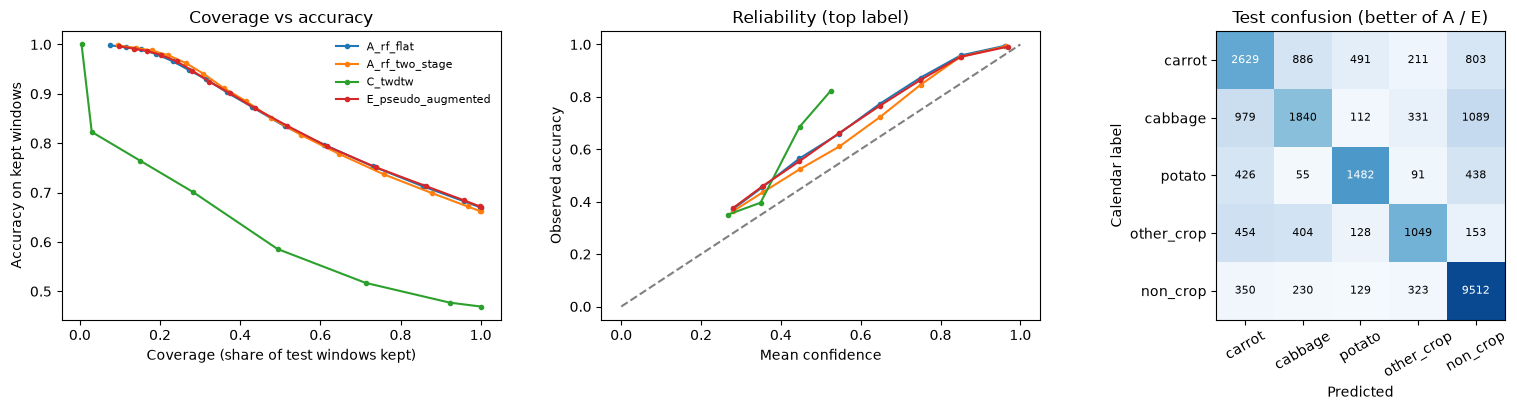

In [10]:
all_results = pd.DataFrame(results).T
all_results.drop(columns="confusion").to_csv(OUTPUT / "experiment_metrics.csv")
display(all_results[metric_columns])

figure, (left, middle, right) = plt.subplots(1, 3, figsize=(16, 4.2))
truth = test["label"].to_numpy()
for name in ("A_rf_flat", "A_rf_two_stage", "C_twdtw", "E_pseudo_augmented"):
    proba = probabilities[name]
    confidence, correct = proba.max(1), np.asarray(CLASSES)[proba.argmax(1)] == truth
    thresholds = np.linspace(0.2, 0.95, 16)
    coverage = [(confidence >= t).mean() for t in thresholds]
    accuracy = [correct[confidence >= t].mean() if (confidence >= t).any() else np.nan for t in thresholds]
    left.plot(coverage, accuracy, "-o", ms=3, label=name)
    bins = np.linspace(0, 1, 11)
    centers, observed = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (confidence > lo) & (confidence <= hi)
        if mask.sum() >= 20:
            centers.append(confidence[mask].mean())
            observed.append(correct[mask].mean())
    middle.plot(centers, observed, "-o", ms=3, label=name)
left.set_xlabel("Coverage (share of test windows kept)")
left.set_ylabel("Accuracy on kept windows")
left.set_title("Coverage vs accuracy")
left.legend(frameon=False, fontsize=8)
middle.plot([0, 1], [0, 1], "--", color="grey")
middle.set_xlabel("Mean confidence")
middle.set_ylabel("Observed accuracy")
middle.set_title("Reliability (top label)")
matrix = np.asarray(results["E_pseudo_augmented" if results["E_pseudo_augmented"]["macro_f1"] > results["A_rf_flat"]["macro_f1"] else "A_rf_flat"]["confusion"])
shares = matrix / np.maximum(matrix.sum(1, keepdims=True), 1)
right.imshow(shares, cmap="Blues", vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        right.text(j, i, f"{matrix[i, j]}", ha="center", va="center", fontsize=8, color="white" if shares[i, j] > 0.5 else "black")
right.set_xticks(range(len(CLASSES)), CLASSES, rotation=30)
right.set_yticks(range(len(CLASSES)), CLASSES)
right.set_title("Test confusion (better of A / E)")
right.set_xlabel("Predicted")
right.set_ylabel("Calendar label")
figure.tight_layout()
figure.savefig(FIGURES / "coverage_calibration_confusion.png", dpi=150)
plt.show()

## 10. Maps for the clearest year

The map year is the complete year whose three map windows leave the most ROI pixels with at least 4 clear composites of 6 (the table below). The last year is only a candidate if its November-January window has data.

One map per 3-month window of that year, following Area 2's rotation: March-May (potato), July-September (cabbage) and November-January (carrot). The model is E if pseudo-labels helped in the inner years, otherwise A. Pixels with top probability < 0.6 are uncertain (light grey). Pixels without a prediction are hatched: dots where the window has fewer than 4 clear composites (clouds), diagonal lines where no composite from 2019-2026 has data (the composites do not cover the western part of the area of interest, outside the Atok boundary). The second row is the top-class probability of every predicted pixel; 0.2 is what a random guess over 5 classes would give. Each map is saved as a GeoTIFF (band 1 class code, band 2 probability).

Share of ROI pixels with enough clear composites for a map window:


,Mar-May,Jul-Sep,Nov-Jan,mean
year,,,,
2019,88%,0%,88%,58%
2020,76%,51%,36%,55%
2021,88%,12%,88%,62%
2022,83%,26%,88%,65%
2023,87%,11%,88%,62%
2024,88%,69%,88%,81%
2025,87%,38%,88%,71%


Map year: 2024 (a test year)


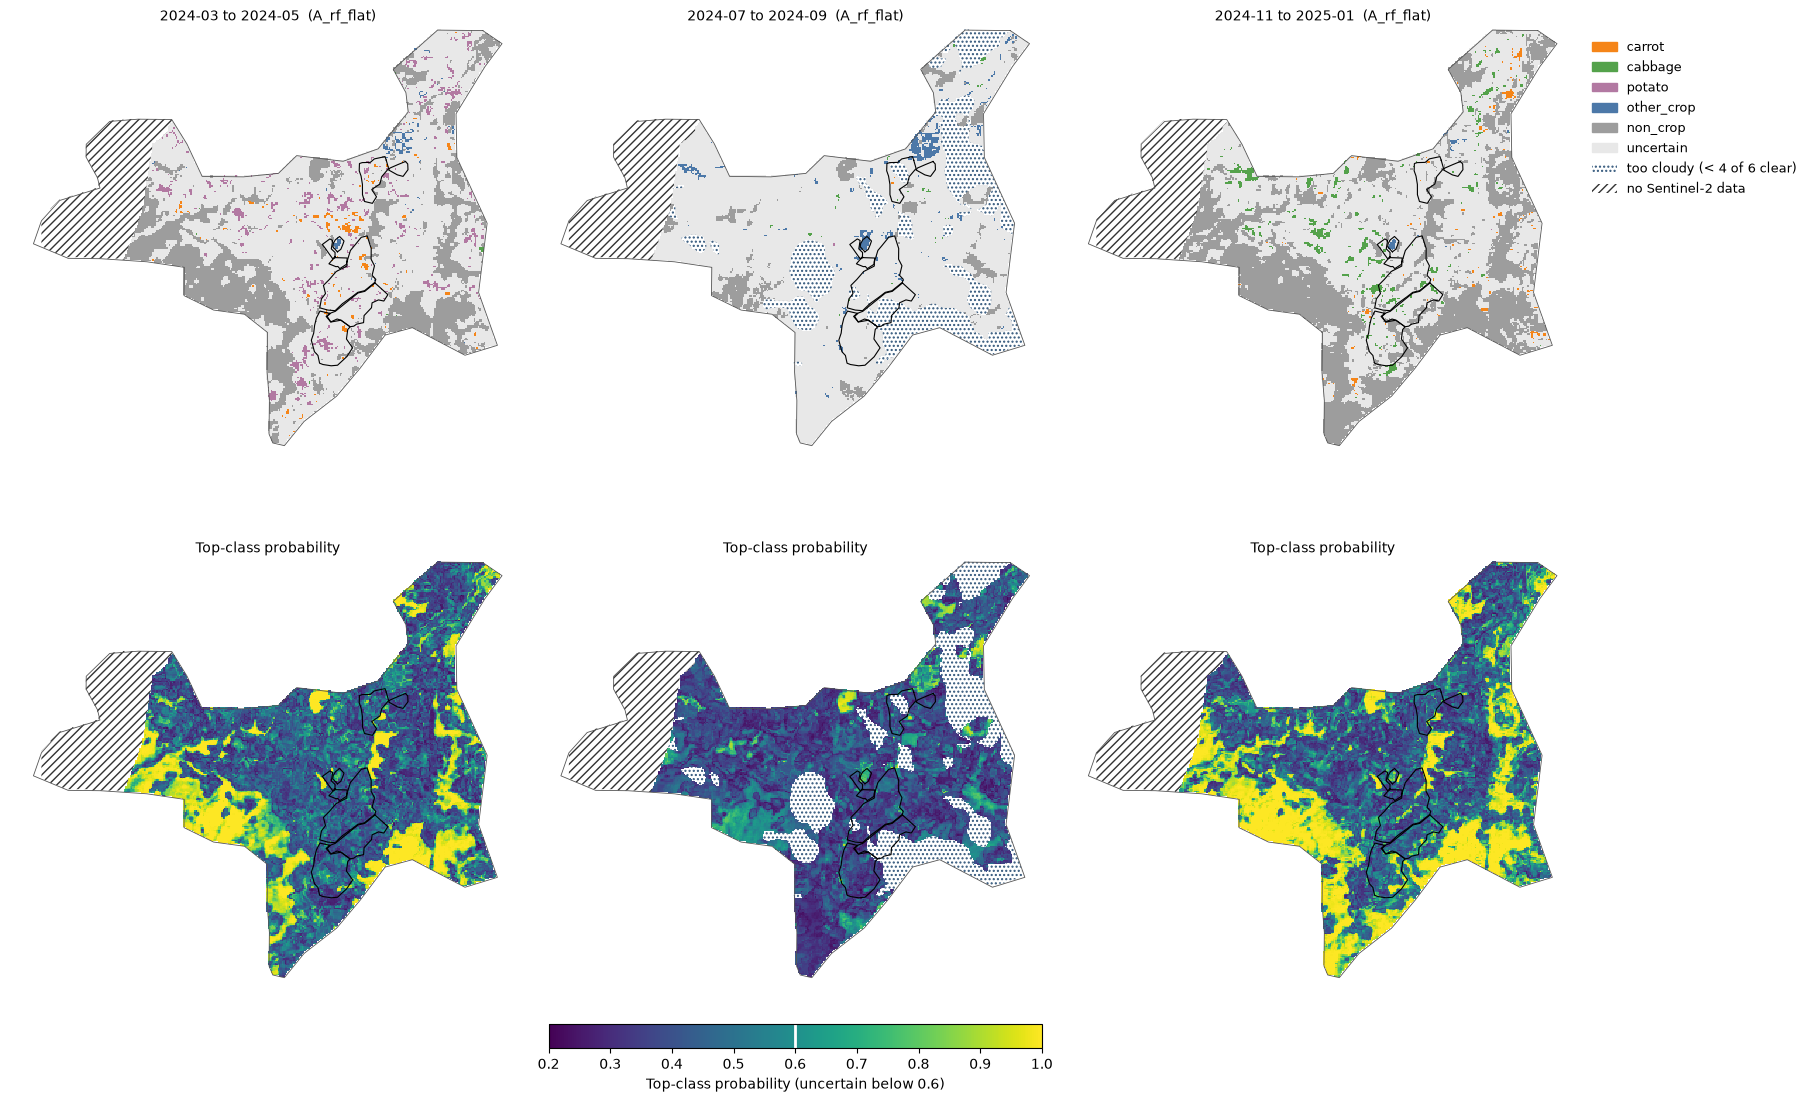

Class shares are of the predicted pixels; the last two columns are pixels without a prediction.


,carrot,cabbage,potato,other_crop,non_crop,uncertain,mapped_pixels,too_cloudy_pixels,no_imagery_pixels
window,,,,,,,,,
2024-03_to_2024-05,1%,0%,4%,1%,26%,69%,36006,0,5109
2024-07_to_2024-09,0%,0%,0%,2%,7%,91%,28447,7559,5109
2024-11_to_2025-01,1%,3%,0%,0%,38%,58%,36006,0,5109


In [11]:
map_model = augmented if not pd.isna(TAU) else baseline_model
map_name = "E_pseudo_augmented" if not pd.isna(TAU) else "A_rf_flat"
MAP_MONTHS = (3, 7, 11)
roi_clear = np.isfinite(cube).all(axis=1)[:, roi_mask]  # (T, ROI pixels)
map_coverage = {}
for year in YEARS:
    starts = [i for i, (y, m, h) in enumerate(SLOTS) if y == year and h == 1 and m in MAP_MONTHS and i + WINDOW <= len(SLOTS)]
    if len(starts) == len(MAP_MONTHS):
        map_coverage[year] = [(roi_clear[s:s + WINDOW].sum(0) >= MIN_VALID).mean() for s in starts]
map_coverage = pd.DataFrame(map_coverage, index=["Mar-May", "Jul-Sep", "Nov-Jan"]).T.rename_axis("year")
map_coverage["mean"] = map_coverage.mean(axis=1)
MAP_YEAR = int(map_coverage["mean"].idxmax())
print("Share of ROI pixels with enough clear composites for a map window:")
display(map_coverage.style.format("{:.0%}"))
print(f"Map year: {MAP_YEAR} ({'a test' if MAP_YEAR in TEST_YEARS else 'a training'} year)")
map_starts = [i for i, (y, m, h) in enumerate(SLOTS) if y == MAP_YEAR and h == 1 and m in MAP_MONTHS]
roi_rows, roi_cols = np.nonzero(roi_mask)
figure, axes = plt.subplots(2, len(map_starts), figsize=(6 * len(map_starts), 11), layout="constrained")
palette = ListedColormap([COLORS[c] for c in CLASSES] + ["#E8E8E8"])
legend_names = CLASSES + ["uncertain"]
never_clear = ~np.isfinite(cube).all(axis=1).any(0)  # no clear composite at all in 2019-2026
MISSING_STYLES = {"too cloudy (< 4 of 6 clear)": ("....", "#30557A"), "no Sentinel-2 data": ("////", "#333333")}


def draw_outlines(axis):
    inverse = ~WINDOW_TRANSFORM
    for geom, color, width in [(geom, "black", 0.8) for geom in polygons["grid_geometry"]] + [(roi_grid, "#555555", 0.6)]:
        xs, ys = geom.exterior.xy
        px = [inverse * (x, y) for x, y in zip(xs, ys)]
        axis.plot([p[0] for p in px], [p[1] for p in px], color=color, lw=width)


def hatch_missing(axis, masks):
    for (hatch, color), mask in zip(MISSING_STYLES.values(), masks):
        if mask.any():
            hatched = axis.contourf(mask.astype(float), levels=[0.5, 1.5], colors="none", hatches=[hatch])
            hatched.set_edgecolor(color)
            hatched.set_linewidth(0)


map_records, map_layers = [], []  # map_layers feeds the section 13 site
for (axis, probability_axis), start in zip(axes.T, map_starts):
    map_meta, map_arrays = extract_windows(roi_rows, roi_cols, starts=[start])
    proba = aligned_proba(map_model, window_features(map_meta, map_arrays)[FEATURE_COLUMNS].to_numpy())
    classes_map = np.full((H, W), np.nan)
    probability_map = np.full((H, W), np.nan)
    r, c = roi_rows[map_meta["pixel_index"]], roi_cols[map_meta["pixel_index"]]
    code = proba.argmax(1).astype(float)
    code[proba.max(1) < 0.6] = len(CLASSES)
    classes_map[r, c], probability_map[r, c] = code, proba.max(1)
    top_class_map = np.full((H, W), np.nan)
    top_class_map[r, c] = proba.argmax(1)
    map_layers.append({"start": start, "top_class": top_class_map, "probability": probability_map})
    year, month, _ = SLOTS[start]
    label = f"{year}-{month:02d}_to_{SLOTS[start + WINDOW - 1][0]}-{SLOTS[start + WINDOW - 1][1]:02d}"
    with rasterio.open(OUTPUT / f"map_{label}.tif", "w", driver="GTiff", height=H, width=W, count=2, dtype="float32",
                       crs=GRID_CRS, transform=WINDOW_TRANSFORM, nodata=np.nan) as destination:
        destination.write(classes_map.astype("float32"), 1)
        destination.write(probability_map.astype("float32"), 2)
        destination.update_tags(classes=",".join(legend_names), model=map_name, provenance="weak calendar labels + NAMRIA ELUM 2023 non-crop" + (" + pseudo-labels" if map_name.startswith("E") else ""))
    missing = [roi_mask & ~np.isfinite(classes_map) & ~never_clear, roi_mask & never_clear]  # too cloudy, no imagery
    axis.imshow(classes_map, cmap=palette, vmin=-0.5, vmax=len(legend_names) - 0.5, interpolation="nearest")
    probability_image = probability_axis.imshow(probability_map, cmap="viridis", vmin=0.2, vmax=1.0, interpolation="nearest")
    for each in (axis, probability_axis):
        hatch_missing(each, missing)
        draw_outlines(each)
        each.axis("off")
    axis.set_title(f"{label.replace('_', ' ')}  ({map_name})", fontsize=10)
    probability_axis.set_title("Top-class probability", fontsize=10)
    shares = pd.Series(code).map(dict(enumerate(legend_names))).value_counts(normalize=True)
    map_records.append({"window": label, **{name: shares.get(name, 0.0) for name in legend_names}, "mapped_pixels": len(code),
                        "too_cloudy_pixels": int(missing[0].sum()), "no_imagery_pixels": int(missing[1].sum())})
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS.get(n, "#E8E8E8")) for n in legend_names]
handles[-1] = plt.Rectangle((0, 0), 1, 1, color="#E8E8E8")
handles += [mpatches.Patch(facecolor="white", edgecolor=color, hatch=hatch, lw=0) for hatch, color in MISSING_STYLES.values()]
axes[0, -1].legend(handles, legend_names + list(MISSING_STYLES), loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False, fontsize=9)
colorbar = figure.colorbar(probability_image, ax=axes[1].tolist(), orientation="horizontal", fraction=0.05, shrink=0.6,
                           label="Top-class probability (uncertain below 0.6)")
colorbar.ax.axvline(0.6, color="white", lw=2)
figure.savefig(FIGURES / f"time_indexed_maps_{MAP_YEAR}.png", dpi=150)
plt.show()
print("Class shares are of the predicted pixels; the last two columns are pixels without a prediction.")
display(pd.DataFrame(map_records).set_index("window").style.format({n: "{:.0%}" for n in legend_names}))

## 11. Next steps toward ground truth

Sections 1-10 only measure agreement with the calendars. This section prepares for real crop observations. Field visits are not possible, so observations would come from farmer calls, agriculture office records, Google Street View or Google Earth historical imagery.

- 11.1 saves the section 4 RF results as the baseline
- 11.2 sets up the observation files
- 11.3 lists 45 fields to check remotely
- 11.4 describes each field's growth cycles
- 11.5 tests on unseen fields
- 11.6 decides whether pseudo-labels are allowed

### 11.1 Baseline

The section 4 RF results are saved once to `baseline_calendar_agreement_v1.json` and not overwritten after that. These are calendar agreement scores, not accuracy. The leave-one-polygon-out recalls saved with them are the more important numbers.

In [12]:
baseline_path = OUTPUT / "baseline_calendar_agreement_v1.json"
baseline_record = {
    "meaning": "agreement with KML calendar labels in held-out years 2024-2026; not ground-truth accuracy",
    "model": "A_rf_flat (section 4)",
    "test_years": list(TEST_YEARS),
    "metrics": {key: value for key, value in results["A_rf_flat"].items() if key != "confusion"},
    "confusion": {"classes": CLASSES, "matrix": results["A_rf_flat"]["confusion"]},
    "leave_one_polygon_out": lopo.to_dict("records"),
}
if not baseline_path.is_file():
    baseline_path.write_text(json.dumps(baseline_record, indent=2, default=float))
    print("Baseline saved:", baseline_path.name)
else:
    print("Baseline already saved; keeping the original:", baseline_path.name)
baseline_saved = json.loads(baseline_path.read_text())
if not np.isclose(baseline_saved["metrics"]["macro_f1"], results["A_rf_flat"]["macro_f1"], atol=1e-6):
    print(f"WARNING: the saved baseline (macro-F1 {baseline_saved['metrics']['macro_f1']:.3f}) does not match this run "
          f"({results['A_rf_flat']['macro_f1']:.3f}). Sections 11.6 and 12 compare against the saved file; "
          f"delete {baseline_path.name} and baseline0_rf.joblib to refresh it.")
print(f"Calendar agreement (macro-F1): {baseline_saved['metrics']['macro_f1']:.3f}")
display(pd.DataFrame(baseline_saved["leave_one_polygon_out"])[["class", "held_out", "status", "recall"]])

Baseline already saved; keeping the original: baseline_calendar_agreement_v1.json
Calendar agreement (macro-F1): 0.592


,class,held_out,status,recall
0,carrot,B1,tested,0.057
1,carrot,Area 2,tested,0.071
2,cabbage,B1,tested,0.206
3,cabbage,Area 3,tested,0.292
4,cabbage,Area 2,tested,0.263
5,potato,Area 2,single group: not testable,NaN
6,other_crop,B2,tested,0.007
7,other_crop,Area 5,tested,0.003
8,non_crop,34 non_crop anchor blocks,tested,0.898
9,non_crop: built_up,34 non_crop anchor blocks,tested,0.726


### 11.2 Observation files

Each observation needs the crop and a date. Two files go in the output folder:

- `field_boundaries.kml`: one polygon per field, named with its `field_id` (for example drawn in Google My Maps and exported as KML)
- `field_observations.csv`: one row per observation, with the columns in `field_observations_template.csv`

| Column | Meaning |
|---|---|
| `field_id` | Same as the polygon name |
| `crop` | `carrot`, `cabbage`, `potato`, `other_crop` (write the crop in `notes`) or `non_crop` |
| `observation_date` | When the crop was in the field (YYYY-MM-DD). Can be left blank if `planting_date` and `harvest_date` are given; the midpoint is used |
| `planting_date`, `harvest_date` | If known (YYYY-MM-DD; use the 15th if only the month is known) |
| `growth_stage` | If known, e.g. `seedling`, `vegetative`, `heading`, `tuber_bulking`, `harvest_ready`, `fallow` |
| `evidence` | `farmer_call`, `office_record`, `street_view` or `high_res_imagery` |
| `source_detail` | Farmer or office name, Street View date, imagery date |
| `photo_path`, `observer`, `notes` | Supporting details (screenshots are fine) |

Sources:

| Source | Useful for | Limitations |
|---|---|---|
| Farmer call (with the field shown on a map) | Crop, planting and harvest months | Dates from memory; make sure it is the right field |
| Municipal Agriculture Office / DA records | Planting reports, registries, insurance records | Locations may only be at barangay level |
| Google Street View (Halsema Highway) | Dated photos of fields along the road; cabbage is the easiest to see | Only near roads; carrot and potato are hard to tell apart |
| Google Earth historical imagery | Whether a field is planted, bare or not farmed on a date | Usually cannot tell carrot from potato |

The section still runs without these files, using the calendar labels.

In [13]:
OBSERVATION_COLUMNS = ["field_id", "crop", "observation_date", "planting_date", "harvest_date", "growth_stage",
                       "evidence", "source_detail", "photo_path", "observer", "notes"]
EVIDENCE_TYPES = {"farmer_call", "office_record", "street_view", "high_res_imagery"}
template_path = OUTPUT / "field_observations_template.csv"
if not template_path.is_file():
    pd.DataFrame(columns=OBSERVATION_COLUMNS).to_csv(template_path, index=False)
observations_path = Path(local_settings.get("atok_observations_path", OUTPUT / "field_observations.csv")).expanduser()
boundaries_path = Path(local_settings.get("atok_boundaries_path", OUTPUT / "field_boundaries.kml")).expanduser()


def load_observed_fields():
    if not (observations_path.is_file() and boundaries_path.is_file()):
        return pd.DataFrame(columns=OBSERVATION_COLUMNS), {}
    observed = pd.read_csv(observations_path, dtype=str).dropna(subset=["field_id", "crop"])
    bad_crops = set(observed["crop"]) - set(CLASSES)
    if bad_crops:
        raise ValueError(f"Unknown crop names in {observations_path.name}: {sorted(bad_crops)}")
    bad_evidence = set(observed["evidence"].dropna()) - EVIDENCE_TYPES
    if bad_evidence:
        raise ValueError(f"Unknown evidence types: {sorted(bad_evidence)}; use {sorted(EVIDENCE_TYPES)}")
    for column in ("observation_date", "planting_date", "harvest_date"):
        observed[column] = pd.to_datetime(observed[column], errors="coerce")
    # use the midpoint of planting and harvest when there is no observation date
    midpoint = observed["planting_date"] + (observed["harvest_date"] - observed["planting_date"]) / 2
    observed["observation_date"] = observed["observation_date"].fillna(midpoint)
    undated = observed["observation_date"].isna()
    if undated.any():
        print(f"Skipping {int(undated.sum())} observation(s) with no observation date and no planting+harvest dates")
    observed = observed[~undated]
    boundaries = read_kml(boundaries_path)
    boundaries["grid_geometry"] = [shapely_transform(g, lambda xy: np.column_stack(to_grid.transform(xy[:, 0], xy[:, 1])))
                                   for g in boundaries["geometry"]]
    geometries = dict(zip(boundaries["name"], boundaries["grid_geometry"]))
    missing = sorted(set(observed["field_id"]) - set(geometries))
    if missing:
        raise ValueError(f"Observations without a boundary in {boundaries_path.name}: {missing}")
    return observed, {field: geometries[field] for field in observed["field_id"].unique()}


observed, observed_geometries = load_observed_fields()
print(f"Observation template: {template_path}")
print(f"Observed fields loaded: {len(observed_geometries)} ({len(observed)} dated observations)")
if len(observed):
    display(observed.pivot_table(index="evidence", columns="crop", values="field_id", aggfunc="nunique", fill_value=0))

Observation template: /Users/almiravelasquez/workspaces/external-crop-data-classification/sen4agrinet_work/analysis/atok_weak_supervision_v2/field_observations_template.csv
Observed fields loaded: 0 (0 dated observations)


### 11.3 Fields to check remotely

Candidates come from the model's probability maps for the section 10 map year, using the window where each crop is easiest to see: potato in March-May, cabbage in July-September and carrot in November-January. A pixel is a candidate if it is more than 50 m from all KML polygons, has an NDVI amplitude of at least 0.15 in that window, and has the crop in its top two classes with probability >= 0.25. Candidates are ranked by uncertainty and kept at least 150 m apart, 15 per crop, starting with potato since it is only in one field so far.

Each row has a Google Maps link to use when asking a farmer or the agriculture office, or when checking Street View and Google Earth. Record the crop that was actually there, even if it differs from `check_for`.

potato: 12,186 eligible pixels -> 15 sites


carrot: 9,843 eligible pixels -> 15 sites


cabbage: 10,487 eligible pixels -> 15 sites
Saved: /Users/almiravelasquez/workspaces/external-crop-data-classification/sen4agrinet_work/analysis/atok_weak_supervision_v2/candidate_check_sites.csv


,site_id,check_for,lon,lat,ask_about_months,model_probability,model_top_class,uncertainty
0,POT-01,potato,120.766,16.636,Mar-Jun,0.62,potato,0.74
1,POT-02,potato,120.751,16.625,Mar-Jun,0.63,potato,0.73
2,POT-03,potato,120.755,16.626,Mar-Jun,0.64,potato,0.72
3,POT-04,potato,120.758,16.628,Mar-Jun,0.64,potato,0.71
4,POT-05,potato,120.761,16.619,Mar-Jun,0.62,potato,0.73
5,POT-06,potato,120.765,16.633,Mar-Jun,0.64,potato,0.71
6,POT-07,potato,120.763,16.635,Mar-Jun,0.64,potato,0.72
7,POT-08,potato,120.765,16.621,Mar-Jun,0.64,potato,0.71
8,POT-09,potato,120.767,16.624,Mar-Jun,0.61,potato,0.75
9,POT-10,potato,120.764,16.630,Mar-Jun,0.63,potato,0.72


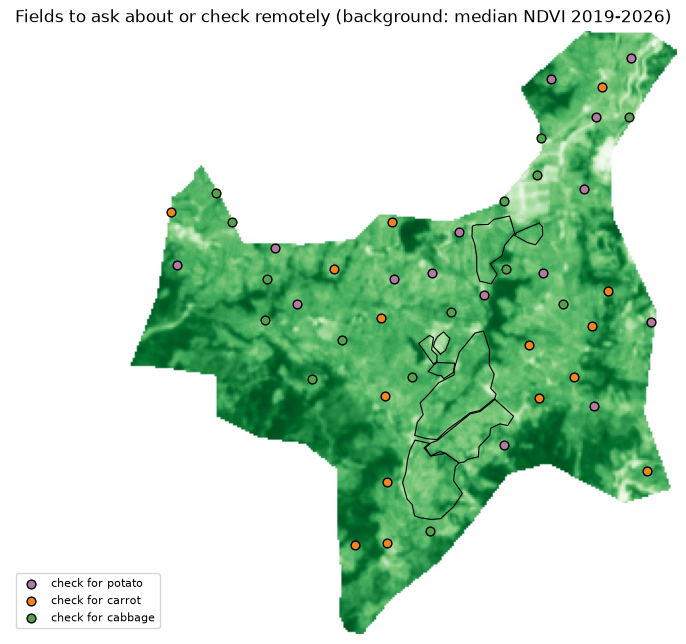

In [14]:
TARGET_CROPS = ["potato", "carrot", "cabbage"]   # selection order: potato first
SITES_PER_CROP = 15
VISIT_WINDOWS = {"potato": 3, "cabbage": 7, "carrot": 11}   # window start month in MAP_YEAR (section 10)
MIN_SPACING_M = 150
far_from_kml = ~np.zeros((H, W), bool)
for geom in polygons["grid_geometry"]:
    far_from_kml &= ~raster_mask(geom.buffer(50))
to_lonlat = Transformer.from_crs(GRID_CRS, "EPSG:4326", always_xy=True)
candidate_rows, chosen_xy = [], []
for crop in TARGET_CROPS:
    start = next(i for i, (y, m, h) in enumerate(SLOTS) if y == MAP_YEAR and m == VISIT_WINDOWS[crop] and h == 1)
    eligible = roi_mask & far_from_kml
    rr, cc = np.nonzero(eligible)
    site_meta, site_arrays = extract_windows(rr, cc, starts=[start])
    site_features = window_features(site_meta, site_arrays)
    proba = aligned_proba(baseline_model, site_features[FEATURE_COLUMNS].to_numpy())
    index = CLASSES.index(crop)
    top_two = np.argsort(-proba, 1)[:, :2]
    keep = ((top_two == index).any(axis=1) & (proba[:, index] >= 0.25) & (site_features["NDVI_amp"].to_numpy() >= 0.15))
    entropy = -(proba * np.log(np.clip(proba, 1e-9, 1))).sum(1) / np.log(len(CLASSES))
    order = np.nonzero(keep)[0][np.argsort(-(entropy[keep] * proba[keep, index]))]
    taken = 0
    for k in order:
        r, c = rr[site_meta["pixel_index"].iloc[k]], cc[site_meta["pixel_index"].iloc[k]]
        x, y = WINDOW_TRANSFORM * (c + 0.5, r + 0.5)
        if any(np.hypot(x - px, y - py) < MIN_SPACING_M for px, py in chosen_xy):
            continue
        chosen_xy.append((x, y))
        lon, lat = to_lonlat.transform(x, y)
        candidate_rows.append({"site_id": f"{crop[:3].upper()}-{taken + 1:02d}", "check_for": crop, "lon": round(lon, 6), "lat": round(lat, 6),
                               "ask_about_months": {"potato": "Mar-Jun", "cabbage": "Jul-Oct", "carrot": "Nov-Feb"}[crop],
                               "maps_link": f"https://www.google.com/maps/@{lat:.6f},{lon:.6f},19z/data=!3m1!1e3",
                               "model_probability": round(float(proba[k, index]), 2), "model_top_class": CLASSES[proba[k].argmax()],
                               "uncertainty": round(float(entropy[k]), 2), "row": r, "col": c})
        taken += 1
        if taken == SITES_PER_CROP:
            break
    print(f"{crop}: {keep.sum():,} eligible pixels -> {taken} sites")
sites = pd.DataFrame(candidate_rows)
sites.drop(columns=["row", "col"]).to_csv(OUTPUT / "candidate_check_sites.csv", index=False)
print("Saved:", OUTPUT / "candidate_check_sites.csv")
display(sites.drop(columns=["row", "col", "maps_link"]).head(15))

figure, axis = plt.subplots(figsize=(7, 6.5))
axis.imshow(np.where(roi_mask, ndvi_med, np.nan), cmap="Greens", vmin=0, vmax=0.9)
for name, geom in polygons["grid_geometry"].items():
    xs, ys = geom.exterior.xy
    px = [~WINDOW_TRANSFORM * (x, y) for x, y in zip(xs, ys)]
    axis.plot([p[0] for p in px], [p[1] for p in px], color="black", lw=0.8)
for crop in TARGET_CROPS:
    rows = sites[sites["check_for"] == crop]
    axis.scatter(rows["col"], rows["row"], s=40, color=COLORS[crop], edgecolor="black", label=f"check for {crop}")
axis.set_title("Fields to ask about or check remotely (background: median NDVI 2019-2026)")
axis.legend(frameon=True, fontsize=8, loc="lower left")
axis.axis("off")
figure.tight_layout()
figure.savefig(FIGURES / "candidate_check_sites.png", dpi=150)
plt.show()

### 11.4 Growth cycles per field

Each field's series is the median of its interior pixels for each half-month (a half-month needs at least half the pixels clear). Gaps of up to two half-months are interpolated and the series is smoothed with a 3-step running median. A cycle is an NDVI peak with prominence >= 0.15, between the lowest points within 6 months on each side, lasting 2-8 months, with at least 60% of its half-months clear.

Cycle features: durations, NDVI at start, peak and end, amplitude and slopes, the NDVI integral, and B5, NDRE, NDMI and B11 at start, peak and end with their changes. The month is not used.

A cycle takes an observed crop if an observation falls within it (plus or minus 15 days). Otherwise it takes the calendar crop if the prior over its months is at least 0.6. `label_source` records which one was used.

46 growth cycles in 5 fields


label,cabbage,carrot,other_crop,unlabeled
field,,,,
Area 2,0,0,0,10
Area 3,12,0,0,0
Area 5,0,0,3,0
B1,0,3,0,6
B2,0,0,12,0


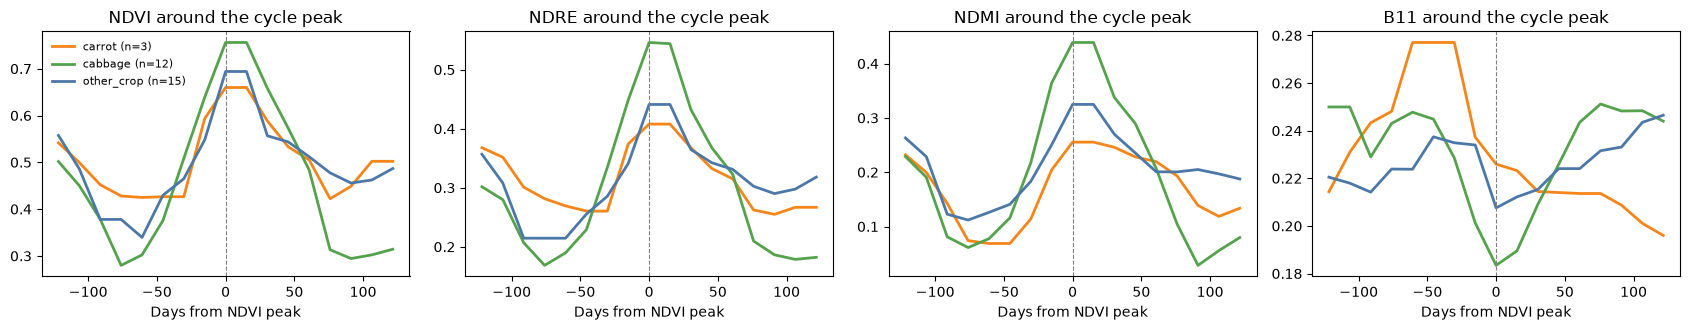

In [15]:
from scipy.signal import find_peaks

CYCLE_VARS = ["NDVI", "NDRE", "NDMI", "B5", "B11"]


def field_median_series(mask):
    rr, cc = np.nonzero(mask)
    values = add_indices(np.moveaxis(cube[:, :, rr, cc], 1, -1))  # (T, N, 8)
    clear = np.isfinite(values).all(-1).mean(1)
    series = np.nanmedian(values, axis=1)
    series[clear < 0.5] = np.nan
    return pd.DataFrame(series, columns=VARS, index=SLOT_DATE)


def detect_cycles(series):
    raw = series["NDVI"]
    filled = series.interpolate(limit=2, limit_area="inside")
    smooth = filled.rolling(3, center=True, min_periods=2).median()
    ndvi = smooth["NDVI"].to_numpy()
    usable = np.where(np.isfinite(ndvi), ndvi, np.nanmin(ndvi) if np.isfinite(ndvi).any() else 0)
    peaks, _ = find_peaks(usable, prominence=0.15, distance=4)
    cycles = []
    for peak in peaks:
        if not np.isfinite(ndvi[peak]):
            continue
        left_range = np.arange(max(0, peak - 12), peak)
        right_range = np.arange(peak + 1, min(len(ndvi), peak + 13))
        left_range, right_range = left_range[np.isfinite(ndvi[left_range])], right_range[np.isfinite(ndvi[right_range])]
        if not len(left_range) or not len(right_range):
            continue
        start, end = left_range[np.argmin(ndvi[left_range])], right_range[np.argmin(ndvi[right_range])]
        if not 4 <= end - start <= 16 or raw.iloc[start:end + 1].notna().mean() < 0.6:
            continue
        values = smooth.iloc[[start, peak, end]]
        days = lambda a, b: (SLOT_DATE[b] - SLOT_DATE[a]).days
        record = {"start_slot": start, "peak_slot": peak, "end_slot": end,
                  "start_date": SLOT_DATE[start].date(), "peak_date": SLOT_DATE[peak].date(), "end_date": SLOT_DATE[end].date(),
                  "duration_days": days(start, end), "greenup_days": days(start, peak), "senescence_days": days(peak, end),
                  "ndvi_integral": float(np.nansum(smooth["NDVI"].iloc[start:end + 1]) * 15.2),
                  "observed_share": float(raw.iloc[start:end + 1].notna().mean())}
        for var in CYCLE_VARS:
            v0, vp, v1 = values[var].to_numpy()
            record.update({f"{var}_start": v0, f"{var}_peak": vp, f"{var}_end": v1,
                           f"{var}_rise": vp - v0, f"{var}_fall": vp - v1})
        record["NDVI_greenup_slope"] = record["NDVI_rise"] / max(record["greenup_days"], 1)
        record["NDVI_senescence_slope"] = record["NDVI_fall"] / max(record["senescence_days"], 1)
        cycles.append(record)
    return cycles, smooth


def cycle_months(start, end):
    return sorted({SLOTS[s][1] for s in range(start, end + 1)})


field_masks = {name: interiors[name] for name in LABEL_AREAS}
field_masks.update({f"observed:{field}": raster_mask(geom, erode=10) & roi_mask for field, geom in observed_geometries.items()})
cycle_records, field_smooth = [], {}
for field, mask in field_masks.items():
    if mask.sum() < 4:
        print(f"{field}: fewer than 4 interior pixels, skipped")
        continue
    series = field_median_series(mask)
    cycles, field_smooth[field] = detect_cycles(series)
    for cycle in cycles:
        label, source = None, "none"
        if field.startswith("observed:"):
            rows = observed[observed["field_id"] == field.split(":", 1)[1]]
            inside = rows[(rows["observation_date"] >= pd.Timestamp(cycle["start_date"]) - pd.Timedelta(days=15))
                          & (rows["observation_date"] <= pd.Timestamp(cycle["end_date"]) + pd.Timedelta(days=15))]
            if inside["crop"].nunique() == 1:
                label, source = inside["crop"].iloc[0], "observed"
        else:
            prior = area_priors[field][[m - 1 for m in cycle_months(cycle["start_slot"], cycle["end_slot"])]].mean(0)
            if prior.max() >= 0.6:
                label, source = CLASSES[prior.argmax()], "calendar"
        cycle_records.append({"field": field, "label": label, "label_source": source, **cycle})
cycles = pd.DataFrame(cycle_records)
CYCLE_FEATURES = [c for c in cycles.columns if c not in {"field", "label", "label_source", "start_slot", "peak_slot", "end_slot",
                                                         "start_date", "peak_date", "end_date", "observed_share"}]
cycles.to_csv(OUTPUT / "field_cycles.csv", index=False)
print(f"{len(cycles)} growth cycles in {cycles['field'].nunique()} fields")
display(cycles.assign(label=cycles["label"].fillna("unlabeled")).pivot_table(index="field", columns="label", values="peak_slot", aggfunc="size", fill_value=0))

figure, axes = plt.subplots(1, 4, figsize=(17, 3.4), sharex=True)
relative = np.arange(-8, 9)
for axis, var in zip(axes, ["NDVI", "NDRE", "NDMI", "B11"]):
    for crop in CROP_CLASSES:
        rows = cycles[cycles["label"] == crop]
        curves = []
        for _, cycle in rows.iterrows():
            smooth = field_smooth[cycle["field"]][var].to_numpy()
            idx = cycle["peak_slot"] + relative
            curve = np.full(len(relative), np.nan)
            ok = (idx >= 0) & (idx < len(smooth))
            curve[ok] = smooth[idx[ok]]
            curves.append(curve)
        if curves:
            axis.plot(relative * 15.2, np.nanmedian(curves, 0), color=COLORS[crop], lw=2, label=f"{crop} (n={len(curves)})")
    axis.axvline(0, color="grey", lw=0.8, ls="--")
    axis.set_title(f"{var} around the cycle peak")
    axis.set_xlabel("Days from NDVI peak")
axes[0].legend(frameon=False, fontsize=8)
figure.tight_layout()
figure.savefig(FIGURES / "cycle_signatures.png", dpi=150)
plt.show()

### 11.5 Unseen fields

An RF on the cycle features is tested leave-one-field-out, so no cycle from the held-out field is used in training. Results are given per crop, with the share of cycles where the model abstains (top probability < 0.6). A crop that is only in one field cannot be tested. Observed labels are used when available, otherwise calendar labels.

In [16]:
ABSTAIN_BELOW = 0.6


def leave_one_field_out(frame, label_sources):
    data = frame[frame["label"].notna() & frame["label_source"].isin(label_sources)].reset_index(drop=True)
    records = []
    for field in data["field"].unique():
        fit_rows, held = data[data["field"] != field], data[data["field"] == field]
        if fit_rows["label"].nunique() < 2:
            continue
        model = RandomForestClassifier(n_estimators=300, min_samples_leaf=1, random_state=SEED, n_jobs=-1,
                                       class_weight="balanced").fit(fit_rows[CYCLE_FEATURES].to_numpy(), fit_rows["label"])
        proba = model.predict_proba(held[CYCLE_FEATURES].to_numpy())
        for (_, row), p in zip(held.iterrows(), proba):
            supported = row["label"] in set(fit_rows["label"])
            records.append({"field": field, "truth": row["label"], "prediction": model.classes_[p.argmax()],
                            "confidence": p.max(), "supported": supported})
    return pd.DataFrame(records)


def per_crop_report(predictions, crops=("carrot", "cabbage", "potato")):
    rows = []
    for crop in crops:
        truth_rows = predictions[predictions["truth"] == crop]
        fields = truth_rows["field"].nunique()
        if not len(truth_rows) or not truth_rows["supported"].any():
            rows.append({"crop": crop, "fields": fields, "cycles": len(truth_rows), "status": f"not testable ({fields} labeled field(s); needs 2+)"})
            continue
        answered = truth_rows[truth_rows["confidence"] >= ABSTAIN_BELOW]
        predicted_as = predictions[(predictions["prediction"] == crop) & (predictions["confidence"] >= ABSTAIN_BELOW)]
        rows.append({"crop": crop, "fields": fields, "cycles": len(truth_rows), "status": "tested",
                     "recall_all": float((truth_rows["prediction"] == crop).mean()),
                     "abstention_rate": 1 - len(answered) / len(truth_rows),
                     "recall_when_answering": float((answered["prediction"] == crop).mean()) if len(answered) else np.nan,
                     "precision_when_answering": float((predicted_as["truth"] == crop).mean()) if len(predicted_as) else np.nan})
    return pd.DataFrame(rows)


label_scope = ["observed"] if (cycles["label_source"] == "observed").any() else ["calendar"]
lofo_predictions = leave_one_field_out(cycles, label_scope)
lofo_report = per_crop_report(lofo_predictions) if len(lofo_predictions) else pd.DataFrame()
lofo_report.to_csv(OUTPUT / "leave_one_field_out_cycles.csv", index=False)
print(f"Labels used for evaluation: {label_scope[0]}"
      + ("" if label_scope == ["observed"] else " (no field observations yet: scores are calendar agreement, not accuracy)"))
display(lofo_report)

Labels used for evaluation: calendar (no field observations yet: scores are calendar agreement, not accuracy)


,crop,fields,cycles,status
0,carrot,1,3,not testable (1 labeled field(s); needs 2+)
1,cabbage,1,12,not testable (1 labeled field(s); needs 2+)
2,potato,0,0,not testable (0 labeled field(s); needs 2+)


### 11.6 Pseudo-label gate

New pseudo-labels are only allowed when:

1. there are at least 5 observed fields each for carrot, cabbage and potato, and
2. the leave-one-field-out recall on those crops, with observed labels, is at least 0.10 higher than the baseline's leave-one-polygon-out recall (11.1).

Until then the uncertain pixels stay unclassified, and the section 8 pseudo-labels are only kept as an experiment.

In [17]:
MIN_OBSERVED_FIELDS = 5
REQUIRED_GAIN = 0.10
observed_cycles = cycles[cycles["label_source"] == "observed"]
observed_field_counts = {crop: observed_cycles.loc[observed_cycles["label"] == crop, "field"].nunique() for crop in TARGET_CROPS}
baseline_lopo = pd.DataFrame(baseline_saved["leave_one_polygon_out"])
baseline_recall = baseline_lopo.loc[baseline_lopo["class"].isin(TARGET_CROPS) & (baseline_lopo["status"] == "tested"), "recall"].mean()
enough_fields = all(count >= MIN_OBSERVED_FIELDS for count in observed_field_counts.values())
observed_recall = np.nan
if enough_fields and label_scope == ["observed"]:
    tested = lofo_report[lofo_report["status"] == "tested"]
    observed_recall = tested.loc[tested["crop"].isin(TARGET_CROPS), "recall_all"].mean()
PSEUDO_LABELS_ALLOWED = bool(enough_fields and np.isfinite(observed_recall) and observed_recall >= baseline_recall + REQUIRED_GAIN)
gate = {"observed_fields": observed_field_counts, "required_per_crop": MIN_OBSERVED_FIELDS,
        "baseline_unseen_field_recall": round(float(baseline_recall), 3),
        "observed_unseen_field_recall": None if not np.isfinite(observed_recall) else round(float(observed_recall), 3),
        "required_gain": REQUIRED_GAIN, "pseudo_labels_allowed": PSEUDO_LABELS_ALLOWED}
(OUTPUT / "pseudo_label_gate.json").write_text(json.dumps(gate, indent=2))
print("Pseudo-label gate:", "OPEN" if PSEUDO_LABELS_ALLOWED else "CLOSED")
for key, value in gate.items():
    print(f"  {key}: {value}")

Pseudo-label gate: CLOSED
  observed_fields: {'potato': 0, 'carrot': 0, 'cabbage': 0}
  required_per_crop: 5
  baseline_unseen_field_recall: 0.178
  observed_unseen_field_recall: None
  required_gain: 0.1
  pseudo_labels_allowed: False


## 12. Testing on unseen fields

Can any method identify carrot, cabbage or potato in a field it was not trained on? Every method below is tested by holding out whole fields. The labels are still from the calendars, and potato is only in Area 2, so potato cannot be tested on a different field.

### 12.1 Baseline 0

The section 4 RF is saved as `baseline0_rf.joblib`, together with its scores from 11.1. The methods below are compared with its leave-one-polygon-out recall for the same crops that section 12 can test, crop by crop. (Only load joblib files from trusted sources.)

In [18]:
import joblib

baseline0_model_path = OUTPUT / "baseline0_rf.joblib"
if not baseline0_model_path.is_file():
    joblib.dump({"model": baseline_model, "feature_columns": FEATURE_COLUMNS, "classes": CLASSES,
                 "window_composites": WINDOW, "train_years": list(TRAIN_YEARS)}, baseline0_model_path)
if joblib.load(baseline0_model_path)["feature_columns"] != FEATURE_COLUMNS:  # our own output file
    print(f"WARNING: {baseline0_model_path.name} was saved with different features; delete it to refresh.")
baseline0 = {"model_file": baseline0_model_path.name, "scores_file": baseline_path.name,
             "calendar_agreement_macro_f1": baseline_saved["metrics"]["macro_f1"],
             "held_out_field_recall_carrot_cabbage": round(float(baseline_recall), 3)}
(OUTPUT / "baseline0_manifest.json").write_text(json.dumps(baseline0, indent=2))
print("Baseline 0:", baseline0)

Baseline 0: {'model_file': 'baseline0_rf.joblib', 'scores_file': 'baseline_calendar_agreement_v1.json', 'calendar_agreement_macro_f1': 0.5915591759453538, 'held_out_field_recall_carrot_cabbage': 0.178}


### 12.2 Pixel cycle table

Cycles are detected for each pixel using the 11.4 rule. Per-pixel detection is used because Area 2 is 5.5 ha and probably contains several plots planted at different times, so its median curve hides their cycles. Each cycle keeps its field name so that whole fields can be held out.

Features are the same as in 11.4, plus the NDVI/NDRE/NDMI curve resampled to 12 points from start to end (for DTW), with the day of year of each point. A cycle is labeled when the field's calendar prior over its green-up months (start to peak) is at least 0.6. Pool pixels give unlabeled cycles for clustering.

In [19]:
CURVE_POINTS = 12
CURVE_VARS = ["NDVI", "NDRE", "NDMI"]


def resample_cycle(smooth, start, end):
    segment = smooth.iloc[start:end + 1][CURVE_VARS].interpolate(limit_direction="both").to_numpy()
    positions = np.linspace(0, len(segment) - 1, CURVE_POINTS)
    curve = np.column_stack([np.interp(positions, np.arange(len(segment)), segment[:, v]) for v in range(len(CURVE_VARS))])
    days = (SLOT_DATE[end] - SLOT_DATE[start]).days
    doy = (SLOT_DATE[start].dayofyear + np.linspace(0, days, CURVE_POINTS)) % 365.25
    return curve, doy


cycle_pixels = pixels[pixels["role"].isin(["label", "pool"])].reset_index(drop=True)
pixel_cycle_rows, cycle_curves, cycle_doys = [], [], []
for _, pixel in cycle_pixels.iterrows():
    series = pd.DataFrame(pixel_series[pixel["pixel_id"]], columns=VARS, index=SLOT_DATE)
    found, smooth = detect_cycles(series)
    for cycle in found:
        field = pixel["area"] if pixel["role"] == "label" else f"pool:{pixel['area']}"
        label, source = None, "none"
        if pixel["role"] == "label":
            growth_months = cycle_months(cycle["start_slot"], cycle["peak_slot"])
            prior = area_priors[pixel["area"]][[m - 1 for m in growth_months]].mean(0)
            if prior.max() >= 0.6 and CLASSES[prior.argmax()] in CROP_CLASSES:
                label, source = CLASSES[prior.argmax()], "calendar"
        curve, doy = resample_cycle(smooth, cycle["start_slot"], cycle["end_slot"])
        pixel_cycle_rows.append({"pixel_id": pixel["pixel_id"], "field": field, "label": label, "label_source": source,
                                 "peak_month": SLOT_DATE[cycle["peak_slot"]].month, **cycle})
        cycle_curves.append(curve)
        cycle_doys.append(doy)
pixel_cycles = pd.DataFrame(pixel_cycle_rows)
cycle_curves, cycle_doys = np.stack(cycle_curves), np.stack(cycle_doys)
pixel_cycles[np.isfinite(pixel_cycles[CYCLE_FEATURES]).all(axis=1)].to_csv(OUTPUT / "pixel_cycles.csv", index=False)
finite_cycles = np.isfinite(pixel_cycles[CYCLE_FEATURES].to_numpy()).all(axis=1) & np.isfinite(cycle_curves).all((1, 2))
pixel_cycles, cycle_curves, cycle_doys = pixel_cycles[finite_cycles].reset_index(drop=True), cycle_curves[finite_cycles], cycle_doys[finite_cycles]
known = pixel_cycles["label"].notna().to_numpy()
print(f"{len(pixel_cycles):,} pixel cycles: {known.sum():,} labeled in {pixel_cycles.loc[known, 'field'].nunique()} fields, "
      f"{(~known).sum():,} unlabeled")
display(pixel_cycles[known].pivot_table(index="field", columns="label", values="pixel_id", aggfunc="size", fill_value=0))
fields_per_crop = pixel_cycles[known].groupby("label")["field"].nunique()
print("Fields per crop:", fields_per_crop.to_dict())

26,091 pixel cycles: 4,310 labeled in 5 fields, 21,781 unlabeled


label,cabbage,carrot,other_crop,potato
field,,,,
Area 2,265,483,0,922
Area 3,293,0,0,0
Area 5,0,0,123,0
B1,240,1378,0,0
B2,0,0,606,0


Fields per crop: {'cabbage': 3, 'carrot': 2, 'other_crop': 2, 'potato': 1}


### 12.3 Growth curves for Areas 2 and 3

Median NDVI, NDRE and NDMI for 2019-2026. Dots are the observed half-months, the line is the smoothed series and the grey band is the 25th-75th percentile of the field's pixels. The background colour is the crop the calendar expects in that month (prior >= 0.5). Area 2 rotates potato, cabbage and carrot; Area 3 is cabbage all year.

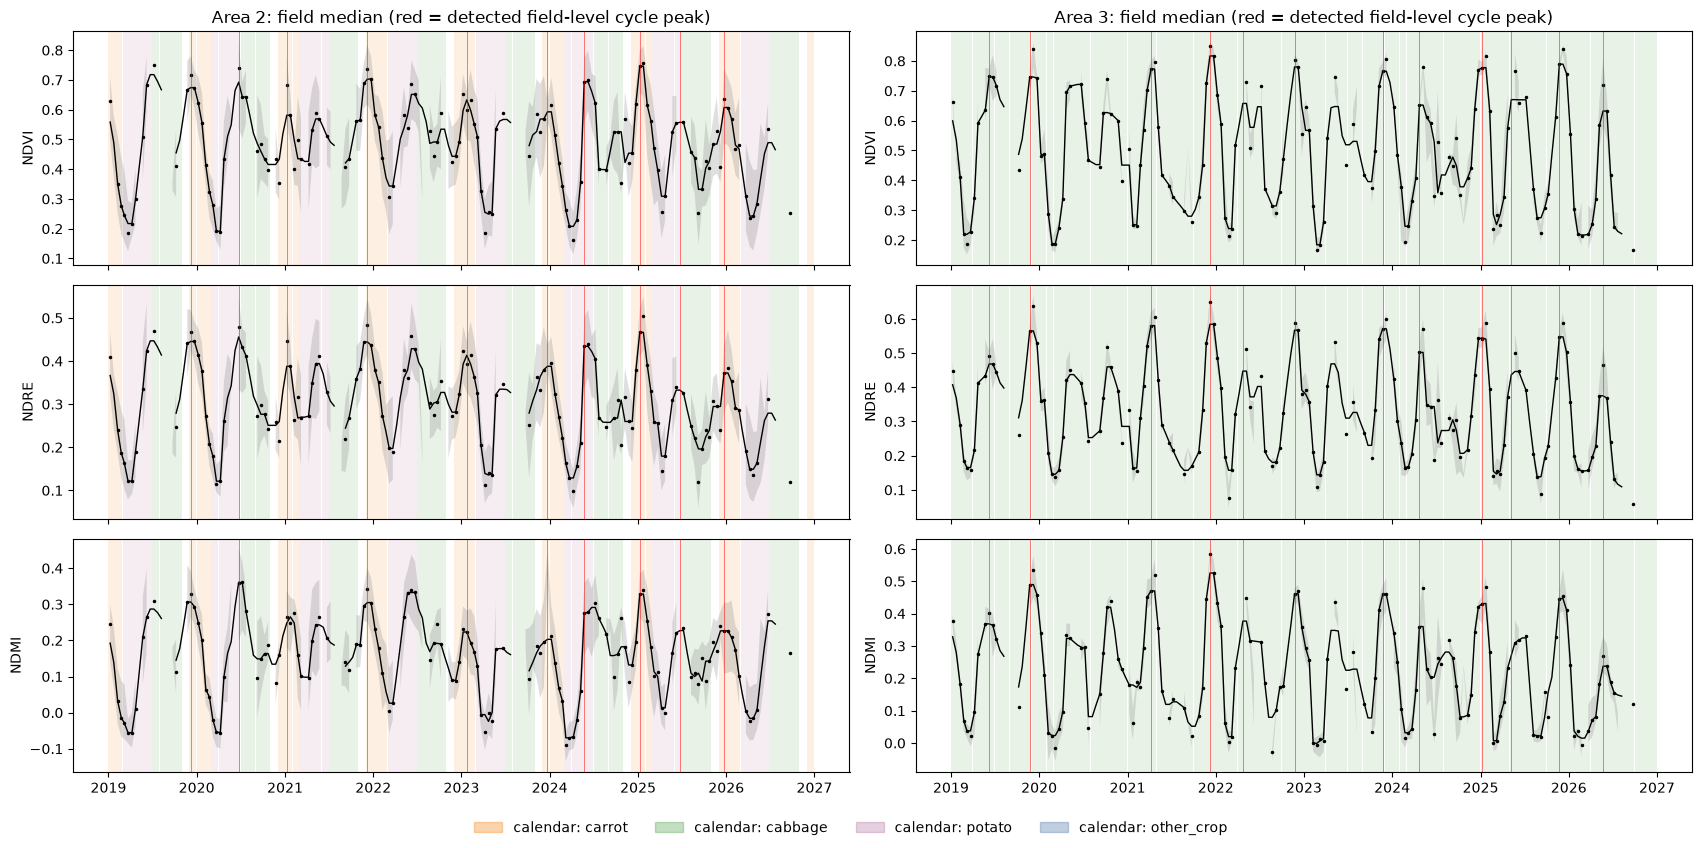

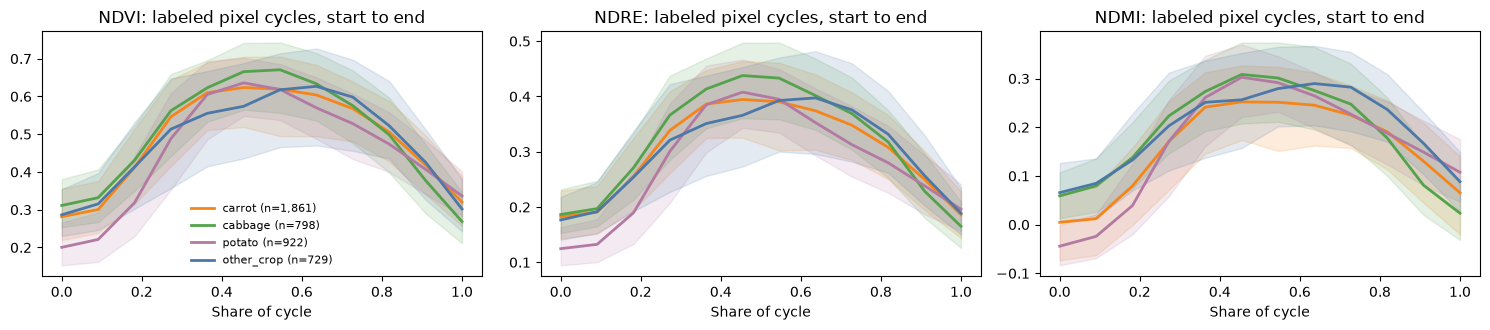

In [20]:
figure, axes = plt.subplots(3, 2, figsize=(17, 8.5), sharex=True)
for column, field in enumerate(["Area 2", "Area 3"]):
    rr, cc = np.nonzero(interiors[field])
    pixel_values = add_indices(np.moveaxis(cube[:, :, rr, cc], 1, -1))
    median_series = field_median_series(interiors[field])
    for row, var in enumerate(CURVE_VARS):
        axis = axes[row, column]
        prior = area_priors[field]
        for year in YEARS:
            for month in range(1, 13):
                crop = CLASSES[prior[month - 1].argmax()]
                if prior[month - 1].max() >= 0.5:
                    axis.axvspan(pd.Timestamp(year, month, 1), pd.Timestamp(year, month, 1) + pd.offsets.MonthEnd(1),
                                 color=COLORS[crop], alpha=0.13, lw=0)
        values = pixel_values[..., VARS.index(var)]
        axis.fill_between(SLOT_DATE, np.nanpercentile(values, 25, 1), np.nanpercentile(values, 75, 1), color="grey", alpha=0.25, lw=0)
        axis.plot(SLOT_DATE, median_series[var], ".", color="black", ms=3)
        axis.plot(SLOT_DATE, field_smooth[field][var], color="black", lw=1)
        for _, cycle in cycles[cycles["field"] == field].iterrows():
            axis.axvline(pd.Timestamp(cycle["peak_date"]), color="red", lw=0.6, alpha=0.6)
        axis.set_ylabel(var)
        if row == 0:
            axis.set_title(f"{field}: field median (red = detected field-level cycle peak)")
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[c], alpha=0.35) for c in CROP_CLASSES]
figure.legend(handles, [f"calendar: {c}" for c in CROP_CLASSES], loc="lower center", ncol=4, frameon=False)
figure.tight_layout(rect=(0, 0.04, 1, 1))
figure.savefig(FIGURES / "area2_area3_growth_curves.png", dpi=150)
plt.show()

figure, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for axis, (v, var) in zip(axes, enumerate(CURVE_VARS)):
    for crop in CROP_CLASSES:
        mask = (pixel_cycles["label"] == crop).to_numpy()
        if mask.sum():
            curves = cycle_curves[mask, :, v]
            axis.plot(np.linspace(0, 1, CURVE_POINTS), np.median(curves, 0), color=COLORS[crop], lw=2, label=f"{crop} (n={mask.sum():,})")
            axis.fill_between(np.linspace(0, 1, CURVE_POINTS), *np.percentile(curves, [25, 75], 0), color=COLORS[crop], alpha=0.15)
    axis.set_title(f"{var}: labeled pixel cycles, start to end")
    axis.set_xlabel("Share of cycle")
axes[0].legend(frameon=False, fontsize=8)
figure.tight_layout()
figure.savefig(FIGURES / "labeled_cycle_signatures.png", dpi=150)
plt.show()

### 12.4 GMM and K-means

Both are fitted on the standardized features of all cycles, without labels. For K = 3 to 10 the table shows the GMM BIC and the K-means silhouette (on 5,000 sampled cycles). Stability is measured with the ARI between five seeds, and between the full fit and fits on 80% subsamples (close to 1 = same clusters each time).

The tables show where the labeled cycles from each field fall. A cluster is only useful for identifying a crop if it holds mostly one crop in several different fields.

In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cycle_scaler = StandardScaler().fit(pixel_cycles[CYCLE_FEATURES])
Zc = cycle_scaler.transform(pixel_cycles[CYCLE_FEATURES])
sample = np.random.default_rng(SEED).choice(len(Zc), min(5000, len(Zc)), replace=False)
selection = []
for k in range(3, 11):
    gmm = GaussianMixture(k, covariance_type="full", random_state=SEED, reg_covar=1e-3, n_init=2).fit(Zc)
    kmeans = KMeans(k, n_init=10, random_state=SEED).fit(Zc)
    selection.append({"k": k, "gmm_bic": gmm.bic(Zc), "kmeans_silhouette": silhouette_score(Zc[sample], kmeans.labels_[sample])})
selection = pd.DataFrame(selection)
GMM_K = int(selection.loc[selection["gmm_bic"].idxmin(), "k"])
KMEANS_K = int(selection.loc[selection["kmeans_silhouette"].idxmax(), "k"])
display(selection)


def stability(make, k):
    seeds = [make(k, s).fit(Zc).predict(Zc) for s in range(5)]
    seed_ari = np.mean([adjusted_rand_score(seeds[i], seeds[j]) for i in range(5) for j in range(i + 1, 5)])
    full = seeds[0]
    rng_local = np.random.default_rng(SEED)
    sub_ari = []
    for _ in range(5):
        subset = rng_local.choice(len(Zc), int(0.8 * len(Zc)), replace=False)
        sub_ari.append(adjusted_rand_score(full, make(k, 0).fit(Zc[subset]).predict(Zc)))
    return seed_ari, float(np.mean(sub_ari))


make_gmm = lambda k, s: GaussianMixture(k, covariance_type="full", random_state=s, reg_covar=1e-3)
make_kmeans = lambda k, s: KMeans(k, n_init=10, random_state=s)
cluster_methods = {"GMM": (make_gmm, GMM_K), "K-means": (make_kmeans, KMEANS_K)}
stability_rows, cluster_ids = [], {}
for name, (make, k) in cluster_methods.items():
    seed_ari, sub_ari = stability(make, k)
    cluster_ids[name] = make(k, SEED).fit(Zc).predict(Zc)
    labeled_ids = cluster_ids[name][known]
    table = pd.crosstab(labeled_ids, pixel_cycles.loc[known, "label"])
    purity = (table.max(axis=1).sum() / table.values.sum()) if table.size else np.nan
    stability_rows.append({"method": name, "k": k, "seed_ARI": seed_ari, "subsample_ARI": sub_ari, "labeled_purity": purity})
display(pd.DataFrame(stability_rows))
for name in cluster_methods:
    composition = pd.crosstab([pixel_cycles.loc[known, "field"], pixel_cycles.loc[known, "label"]], cluster_ids[name][known], normalize="index")
    print(f"{name}: share of each field-crop's labeled cycles in each cluster")
    display(composition.style.format("{:.0%}").background_gradient(axis=None, cmap="Blues"))

,k,gmm_bic,kmeans_silhouette
0,3,-487917.836,0.156
1,4,-519841.845,0.143
2,5,-531356.441,0.127
3,6,-537498.440,0.116
4,7,-544295.874,0.113
5,8,-547554.682,0.109
6,9,-557820.848,0.107
7,10,-563248.514,0.105


,method,k,seed_ARI,subsample_ARI,labeled_purity
0,GMM,10,0.571,0.427,0.453
1,K-means,3,0.997,0.988,0.432


GMM: share of each field-crop's labeled cycles in each cluster


K-means: share of each field-crop's labeled cycles in each cluster


### 12.5 DTW matching

Prototypes are the median 12-point curves of each crop's labeled cycles in the training fields. Each held-out cycle is matched to the prototypes with multivariate DTW and assigned the closest crop, or unknown if the distance is above that crop's 90th percentile in training.

Variants:
- DTW: curve shape only
- TWDTW: adds the day-of-year penalty from section 6
- DTW + calendar: DTW similarity times the regional calendar prior (Areas 1 and 4) over the green-up months; the held-out field's own calendar is not used

Calendar only (regional prior without imagery) is included for comparison. Check its answers in 12.7: if it gives the same crop for every cycle, it is a constant-class baseline, not a calendar method.

In [22]:
def dtw_distances(queries, curve, query_doy=None, curve_doy=None):
    cost = np.linalg.norm(queries[:, :, None, :] - curve[None, None, :, :], axis=-1)
    if query_doy is not None:
        gap = np.abs(query_doy[:, :, None] - curve_doy[None, None, :])
        gap = np.minimum(gap, 365.25 - gap)
        cost = cost + 1 / (1 + np.exp(-ALPHA * (gap - BETA)))
    n, rows, cols = cost.shape
    accumulated = np.full((n, rows + 1, cols + 1), np.inf)
    accumulated[:, 0, 0] = 0
    for i in range(1, rows + 1):
        for j in range(1, cols + 1):
            accumulated[:, i, j] = cost[:, i - 1, j - 1] + np.minimum(np.minimum(accumulated[:, i - 1, j], accumulated[:, i, j - 1]), accumulated[:, i - 1, j - 1])
    return accumulated[:, rows, cols]


def circular_mean_doy(doys):
    angle = np.angle(np.exp(1j * 2 * np.pi * doys / 365.25).mean(0))
    return (angle % (2 * np.pi)) * 365.25 / (2 * np.pi)


def regional_prior_for(frame):
    out = []
    for _, cycle in frame.iterrows():
        months_ = cycle_months(cycle["start_slot"], cycle["peak_slot"])
        prior = regional_prior[[m - 1 for m in months_], :4].mean(0)
        out.append(prior / prior.sum())
    return np.array(out)


def dtw_predict(train_mask, test_mask, seasonal=False, calendar=False):
    crops = [c for c in CROP_CLASSES if ((pixel_cycles["label"] == c).to_numpy() & train_mask).sum() >= 10]
    distances_test, thresholds = [], {}
    for crop in crops:
        members = (pixel_cycles["label"] == crop).to_numpy() & train_mask
        prototype, prototype_doy = np.median(cycle_curves[members], 0), circular_mean_doy(cycle_doys[members])
        args = (cycle_doys[members], prototype_doy) if seasonal else (None, None)
        own = dtw_distances(cycle_curves[members], prototype, *args)
        thresholds[crop] = np.percentile(own, 90)
        args = (cycle_doys[test_mask], prototype_doy) if seasonal else (None, None)
        distances_test.append(dtw_distances(cycle_curves[test_mask], prototype, *args))
    distances_test = np.column_stack(distances_test)
    if calendar:
        temperature = np.median(list(thresholds.values()))
        similarity_ = np.exp(-(distances_test - distances_test.min(1, keepdims=True)) / temperature)
        prior = regional_prior_for(pixel_cycles[test_mask])[:, [CROP_CLASSES.index(c) for c in crops]]
        best = (similarity_ * prior).argmax(1)
    else:
        best = distances_test.argmin(1)
    prediction = np.asarray(crops)[best]
    beyond = distances_test[np.arange(len(best)), best] > np.array([thresholds[c] for c in prediction])
    return np.where(beyond, "unknown", prediction)

### 12.6 Holding out whole fields

Each labeled field is held out in turn, and the prototypes, cluster-to-crop mappings and RF are built from the other fields. All cycles of the held-out field are predicted. A crop that does not occur in the other fields is marked untestable.

| Method | Prediction |
|---|---|
| Cycle RF | RF on cycle features; unknown if top probability < 0.6 |
| GMM / K-means | Crop of the cluster in the other fields; unknown if its top crop is < 50% or < 20 cycles |
| DTW / TWDTW / DTW + calendar | See 12.5 |
| Calendar only | Top crop of the regional prior |

Results are the shares of held-out cycles that are correct, wrong or unknown for each crop. The field-level column is the share of field-crop pairs where the most common answer is correct.

crop,cabbage,carrot,other_crop,mean_correct
method,,,,
Calendar only,0%,0%,100%,33%
DTW (no constraint),47%,17%,1%,22%
TWDTW (season),20%,0%,11%,10%
DTW + calendar,18%,2%,3%,7%
K-means clusters,0%,9%,0%,3%
Cycle RF,6%,1%,0%,2%
GMM clusters,0%,6%,1%,2%
"Baseline 0 (sec. 4 RF, held-out polygons)",25%,6%,0%,11%


,crop,status
3,potato,untestable: crop in one field only


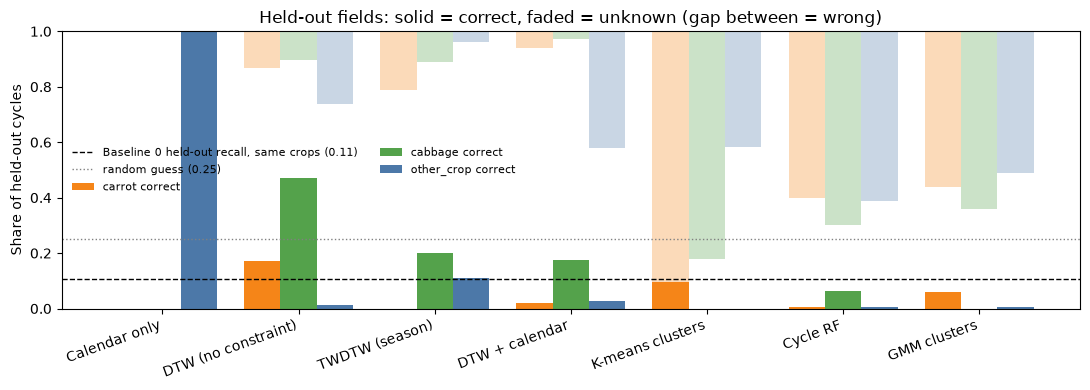

In [23]:
def cluster_predict(ids, train_mask, test_mask):
    train_table = pd.crosstab(ids[train_mask], pixel_cycles.loc[train_mask, "label"])
    mapping = {}
    for cluster, counts in train_table.iterrows():
        mapping[cluster] = counts.idxmax() if counts.max() >= 20 and counts.max() / counts.sum() >= 0.5 else "unknown"
    return np.array([mapping.get(c, "unknown") for c in ids[test_mask]])


def rf_predict(train_mask, test_mask):
    model = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced", n_jobs=-1, random_state=SEED)
    model.fit(pixel_cycles.loc[train_mask, CYCLE_FEATURES], pixel_cycles.loc[train_mask, "label"])
    proba = model.predict_proba(pixel_cycles.loc[test_mask, CYCLE_FEATURES])
    return np.where(proba.max(1) >= 0.6, model.classes_[proba.argmax(1)], "unknown")


def calendar_only_predict(train_mask, test_mask):
    return np.asarray(CROP_CLASSES)[regional_prior_for(pixel_cycles[test_mask]).argmax(1)]


methods = {
    "Cycle RF": rf_predict,
    "GMM clusters": lambda tr, te: cluster_predict(cluster_ids["GMM"], tr, te),
    "K-means clusters": lambda tr, te: cluster_predict(cluster_ids["K-means"], tr, te),
    "DTW (no constraint)": lambda tr, te: dtw_predict(tr, te),
    "TWDTW (season)": lambda tr, te: dtw_predict(tr, te, seasonal=True),
    "DTW + calendar": lambda tr, te: dtw_predict(tr, te, calendar=True),
    "Calendar only": calendar_only_predict,  # regional prior, no imagery
}
held_out_rows = []
labeled_fields = pixel_cycles.loc[known, "field"].unique()
for field in labeled_fields:
    test_mask = known & (pixel_cycles["field"] == field).to_numpy()
    train_mask = known & ~test_mask
    train_crops = set(pixel_cycles.loc[train_mask, "label"])
    truth = pixel_cycles.loc[test_mask, "label"].to_numpy()
    for name, predict in methods.items():
        prediction = predict(train_mask, test_mask)
        for t, p in zip(truth, prediction):
            held_out_rows.append({"method": name, "field": field, "truth": t, "prediction": p, "testable": t in train_crops})
held_out = pd.DataFrame(held_out_rows)
held_out.to_csv(OUTPUT / "held_out_field_predictions.csv", index=False)


def summarize(frame):
    rows = []
    for (method, crop), part in frame.groupby(["method", "truth"]):
        if not part["testable"].any():
            rows.append({"method": method, "crop": crop, "status": "untestable: crop in one field only"})
            continue
        part = part[part["testable"]]
        per_field = part.groupby("field")["prediction"].agg(lambda s: s.mode()[0])
        rows.append({"method": method, "crop": crop, "status": "tested", "fields": part["field"].nunique(), "cycles": len(part),
                     "correct": (part["prediction"] == crop).mean(), "wrong": ((part["prediction"] != crop) & (part["prediction"] != "unknown")).mean(),
                     "unknown": (part["prediction"] == "unknown").mean(),
                     "field_level_correct": (per_field == crop).mean()})
    return pd.DataFrame(rows)


held_out_summary = summarize(held_out)
held_out_summary.to_csv(OUTPUT / "held_out_field_summary.csv", index=False)
tested = held_out_summary[held_out_summary["status"] == "tested"]
overview = (tested.pivot_table(index="method", columns="crop", values="correct")
            .assign(mean_correct=lambda t: t.mean(axis=1)).sort_values("mean_correct", ascending=False))
crops_tested = [c for c in CROP_CLASSES if c in tested["crop"].unique()]
# Baseline 0 on the same crops: its section 4 held-out-polygon recall per crop (pixel windows, so not the same unit as cycles)
BASELINE0_ROW = "Baseline 0 (sec. 4 RF, held-out polygons)"
baseline_per_crop = baseline_lopo[baseline_lopo["status"] == "tested"].groupby("class")["recall"].mean().reindex(crops_tested)
baseline_matched = float(baseline_per_crop.mean())
overview.loc[BASELINE0_ROW, crops_tested] = baseline_per_crop.to_numpy()
overview.loc[BASELINE0_ROW, "mean_correct"] = baseline_matched
display(overview.style.format("{:.0%}", na_rep="-"))
display(tested.pivot_table(index="method", columns="crop", values=["wrong", "unknown"]).style.format("{:.0%}", na_rep="-"))
display(held_out_summary[held_out_summary["status"] != "tested"].drop_duplicates("crop")[["crop", "status"]])

figure, axis = plt.subplots(figsize=(11, 4))
order = overview.index.drop(BASELINE0_ROW)
width = 0.8 / max(len(crops_tested), 1)
for offset, crop in enumerate(crops_tested):
    part = tested[tested["crop"] == crop].set_index("method").reindex(order)
    axis.bar(np.arange(len(order)) + offset * width, part["correct"], width, color=COLORS[crop], label=f"{crop} correct")
    axis.bar(np.arange(len(order)) + offset * width, part["unknown"], width, bottom=part["correct"] + part["wrong"], color=COLORS[crop], alpha=0.3)
axis.axhline(baseline_matched, color="black", ls="--", lw=1, label=f"Baseline 0 held-out recall, same crops ({baseline_matched:.2f})")
axis.axhline(1 / len(CROP_CLASSES), color="grey", ls=":", lw=1, label="random guess (0.25)")
axis.set_xticks(np.arange(len(order)) + width * (len(crops_tested) - 1) / 2, order, rotation=20, ha="right")
axis.set_ylabel("Share of held-out cycles")
axis.set_ylim(0, 1)
axis.set_title("Held-out fields: solid = correct, faded = unknown (gap between = wrong)")
axis.legend(frameon=False, fontsize=8, ncol=2)
figure.tight_layout()
figure.savefig(FIGURES / "held_out_field_comparison.png", dpi=150)
plt.show()

### 12.7 Result

Crop-specific modelling is considered feasible with this data only if an imagery method:

1. beats Baseline 0's held-out recall by at least 0.10 on average over the testable crops (Baseline 0 is averaged over the same crops),
2. beats calendar only (reported with its answers, since it may answer the same crop every time), and
3. beats random guessing (0.25) for every testable crop.

Pseudo-labels also need the 11.6 gate to be open, since these labels still come from the calendars.

In [24]:
imagery_methods = overview.drop(index=["Calendar only", BASELINE0_ROW], errors="ignore")
calendar_score = overview.loc["Calendar only", "mean_correct"] if "Calendar only" in overview.index else np.nan
calendar_answers = held_out.loc[(held_out["method"] == "Calendar only") & held_out["testable"], "prediction"].value_counts(normalize=True)
if len(calendar_answers) == 1:
    print(f"Calendar only answers {calendar_answers.index[0]} for every held-out cycle: it is a constant-class baseline "
          f"({calendar_score:.0%} = the share of testable crops that are {calendar_answers.index[0]}).")
print("Baseline 0 held-out recall per crop:", baseline_per_crop.round(3).to_dict(), f"-> mean {baseline_matched:.3f}")
checks = imagery_methods.assign(
    beats_baseline0=imagery_methods["mean_correct"] >= baseline_matched + 0.10,
    beats_calendar_only=imagery_methods["mean_correct"] > calendar_score,
    beats_random_every_crop=imagery_methods[crops_tested].min(axis=1) > 1 / len(CROP_CLASSES),
)
checks["passes"] = checks[["beats_baseline0", "beats_calendar_only", "beats_random_every_crop"]].all(axis=1)
display(checks[["mean_correct", "beats_baseline0", "beats_calendar_only", "beats_random_every_crop", "passes"]])
best_method = checks["mean_correct"].idxmax()
FEASIBLE = bool(checks["passes"].any())
independent_field_gate = {"best_method": best_method, "best_mean_correct": round(float(checks.loc[best_method, "mean_correct"]), 3),
                          "baseline0_recall_same_crops": round(baseline_matched, 3),
                          "baseline0_recall_per_crop": {c: round(float(v), 3) for c, v in baseline_per_crop.items()},
                          "calendar_only": round(float(calendar_score), 3),
                          "calendar_only_answers": {c: round(float(v), 3) for c, v in calendar_answers.items()},
                          "testable_crops": crops_tested, "untestable_crops": sorted(set(CROP_CLASSES) - set(crops_tested)),
                          "feasible_with_current_data": FEASIBLE,
                          "pseudo_labels_allowed": bool(FEASIBLE and PSEUDO_LABELS_ALLOWED)}
(OUTPUT / "independent_field_gate.json").write_text(json.dumps(independent_field_gate, indent=2))
for key, value in independent_field_gate.items():
    print(f"{key}: {value}")
print("\nFeasible with current data:", FEASIBLE)

Calendar only answers other_crop for every held-out cycle: it is a constant-class baseline (33% = the share of testable crops that are other_crop).
Baseline 0 held-out recall per crop: {'carrot': 0.064, 'cabbage': 0.254, 'other_crop': 0.005} -> mean 0.107


crop,mean_correct,beats_baseline0,beats_calendar_only,beats_random_every_crop,passes
method,,,,,
DTW (no constraint),0.218,True,False,False,False
TWDTW (season),0.104,False,False,False,False
DTW + calendar,0.075,False,False,False,False
K-means clusters,0.032,False,False,False,False
Cycle RF,0.024,False,False,False,False
GMM clusters,0.022,False,False,False,False


best_method: DTW (no constraint)
best_mean_correct: 0.218
baseline0_recall_same_crops: 0.107
baseline0_recall_per_crop: {'carrot': 0.064, 'cabbage': 0.254, 'other_crop': 0.005}
calendar_only: 0.333
calendar_only_answers: {'other_crop': 1.0}
testable_crops: ['carrot', 'cabbage', 'other_crop']
untestable_crops: ['potato']
feasible_with_current_data: False
pseudo_labels_allowed: False

Feasible with current data: False
